# TriFrame: Computer Vision with Deep Learning, end to end

**What this notebook does, in order** (each stage saves its outputs to Hugging Face before the next one starts):

| Stage | Your step | What happens |
|---|---|---|
| 1 | Load the data | 979 US stocks, 25.8 years of daily/hourly bars (2001-01-02 to 2026-10-09), as chart sets: weekly 104, daily 126 and hourly 140 bars, plus 33 numeric features and the labels. Rows from 2023-01-03 on stay sealed. |
| 2 | Split | Train 2001-2016, validation 2017-2019, test 2020-2022, each with a 20-day purge at the boundary. Holdout 2023 onward. |
| 3 | Baselines | Numbers only: constant, HAR volatility model, linear and boosted-tree heads on the 33 features. |
| 4 | Pretrained models | Frozen embeddings of every chart from 7 ImageNet backbones (ResNet-18, EfficientNet-B0, ViT-B/16, ConvNeXt-Tiny, Swin-T, DINOv2-S, MobileNetV3) plus 3 random-weight controls. Resumable. |
| 5 | Combine timeframes and tune | PCA per view, then image-only, numbers + images (all three views) and single-view heads; ridge/logistic paths and a tree grid tuned on validation. Every configuration is logged. |
| 6 | Pick the best model | Pre-registered rule; H2 test; calibration; the NO TRADE thresholds; everything frozen to a config file. |
| 7 | Test | One look at 2020-2022: metrics with month-block confidence intervals, H1 and H3, what NO TRADE avoids, survivorship sensitivity. |
| 8 | Model bundle | Saved, checked against the notebook's own predictions and against the training inputs, pushed to a private model repo. |
| 9 | Dashboard | Gradio app on a Hugging Face Space + the HTML page for krishnaharsha.com ("Computer Vision with Deep Learning Project Dashboard"). |
| 10 | Holdout (owner, once) | Off by default. Opens 2023 onward through the project's holdout guard with your key. |
| 11 | Report | REPORT.md from computed values only; retries any failed upload. |

**Before you run**
1. Runtime > Change runtime type > **A100 GPU** and **High-RAM** (T4 works, about 3x slower).
2. Colab secrets (key icon): **HF_TOKEN** = a Hugging Face token with *write* access. Optional **HF_READ_TOKEN** = a *read-only* token for the dashboard.
3. First run with `QUICK = True` (60 stocks, roughly 45-90 minutes). If everything passes, set `QUICK = False` and run again (several hours; it resumes after a disconnect).

**Rules this notebook enforces:** data only through the sealed `ImageStore`; preprocessing fitted on training rows only; hyper-parameters chosen on validation only; the test years are read once (a second run needs a written reason); the holdout opens only with your key. Expect chart images to add little or nothing to the numbers: the renderer scales each chart to fit its panel, so pictures cannot show the volatility level. The notebook measures this rather than assuming it.

In [1]:
# ==================================== CONFIG: edit here, then Runtime > Run all ====================================
import numpy as np

QUICK = True               # True = smoke test on QUICK_TICKERS stocks (about 45-90 min on an A100). False = full 979-stock run.
QUICK_TICKERS = 60
SEED = 11
HF_USER = "KrishnaHarshaTangirala"
DATA_REPO = f"{HF_USER}/triframe-us-equities-chart-ohlcv"   # existing private dataset: charts, features, labels, project code
RUNS_REPO = f"{HF_USER}/triframe-cv-runs"                   # new private dataset: embeddings, results, figures, ledger, logs
MODEL_REPO = f"{HF_USER}/triframe-cv-model"                 # new private model repo: the frozen bundle the dashboard loads
SPACE_REPO = f"{HF_USER}/triframe-cv-dashboard"             # Gradio Space that krishnaharsha.com embeds
SPACE_PRIVATE = False      # a website iframe needs a public Space; the model files stay in the private MODEL_REPO
UPLOAD = True              # push every stage's outputs to Hugging Face
UPLOAD_EMBEDDINGS = True   # full run = about 20 GB of embeddings; if your Hugging Face storage is too small, set False
                           # (they are then kept on Google Drive instead, which is what lets a run resume after a disconnect)
GRADIO_VERSION = "6.20.0"  # version the dashboard was tested with

SPLITS = {"train": ("2001-01-01", "2017-01-01"),            # fit the models
          "val":   ("2017-01-01", "2020-01-01"),            # tune, select, calibrate, set the NO TRADE rule
          "test":  ("2020-01-01", "2023-01-03")}            # one honest check of the frozen choice (includes COVID-2020)
HOLDOUT_START = "2023-01-03"                                # sealed by holdout_guard; opened once, by the owner, in Stage 10

BACKBONE_NAMES = None      # None = the 7 pretrained backbones + 3 random-weight controls (tfcv_train.BACKBONES)
PCA_DIM = 128              # per backbone and view, fitted on training rows only
ALPHAS = [float(a) for a in np.logspace(-2, 6, 17)]         # ridge grid (volatility)
CS = [float(c) for c in np.logspace(-4, 1, 6)]              # logistic grid (direction, drawdown)
N_BOOT = 1000              # month-block bootstrap resamples for every confidence interval
CHUNK_TICKERS = 40         # embedding work unit: one resumable file per chunk of tickers

In [2]:
# ==================================== SETUP: packages, Drive, Hugging Face, data, integrity ====================================
import os, sys, json, time, math, glob, shutil, hashlib, random, subprocess, warnings, gc, datetime as dt
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

IN_COLAB = "google.colab" in sys.modules
LOCAL_TEST = os.environ.get("TFCV_LOCAL_TEST") == "1"
RUN_TAG = "quick" if QUICK else "full"
DST = os.environ.get("TFCV_DATA_ROOT", "/content/triframe").rstrip("/")
WORK = os.environ.get("TFCV_WORK", "/content/tfcv")
for sub in ("", "results", "figures", "frozen", "bundle", "space", "web", f"emb_{RUN_TAG}", f"pca_{RUN_TAG}"):
    os.makedirs(os.path.join(WORK, sub), exist_ok=True)

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "xgboost", "lightgbm", "yfinance",
                    "huggingface_hub>=0.25", "pyarrow", "pandas_market_calendars"], check=True)
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/triframe_cv"

    def _secret(name):
        try:
            return userdata.get(name)
        except Exception:
            return None
    HF_TOKEN, HF_READ_TOKEN = _secret("HF_TOKEN"), _secret("HF_READ_TOKEN")
else:
    DRIVE_DIR = os.path.join(WORK, "drive_mirror")
    HF_TOKEN, HF_READ_TOKEN = os.environ.get("HF_TOKEN"), None
os.makedirs(DRIVE_DIR, exist_ok=True)
if LOCAL_TEST:
    UPLOAD = False

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE == "cuda" else 0.0
BATCH = 384 if GPU_GB > 30 else 160
print(f"Device: {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU'}, {GPU_GB:.0f} GB) | run: {RUN_TAG} | upload: {UPLOAD}")
if DEVICE != "cuda" and not LOCAL_TEST:
    print("WARNING: no GPU. Runtime > Change runtime type > A100 (or T4). The embedding stage needs a GPU.")

from huggingface_hub import HfApi, snapshot_download, hf_hub_download
api = HfApi(token=HF_TOKEN) if HF_TOKEN else None
if UPLOAD:
    assert HF_TOKEN, "Add a Hugging Face token with WRITE access as the Colab secret HF_TOKEN (key icon on the left)."
    print("Hugging Face user:", api.whoami()["name"])
    for rid, rtype in ((RUNS_REPO, "dataset"), (MODEL_REPO, "model")):
        api.create_repo(rid, repo_type=rtype, private=True, exist_ok=True)

FAILED_UPLOADS = []


def push(local, path_in_repo, repo_id=None, repo_type="dataset", msg=None):
    """Upload a file or folder to Hugging Face. Failures are recorded and retried in Stage 11, never silently dropped."""
    if not UPLOAD:
        return
    repo_id = repo_id or RUNS_REPO
    try:
        if os.path.isdir(local):
            api.upload_folder(folder_path=local, path_in_repo=path_in_repo, repo_id=repo_id, repo_type=repo_type,
                              commit_message=msg or f"update {path_in_repo}")
        else:
            api.upload_file(path_or_fileobj=local, path_in_repo=path_in_repo, repo_id=repo_id, repo_type=repo_type,
                            commit_message=msg or f"update {path_in_repo}")
    except Exception as e:
        FAILED_UPLOADS.append((local, path_in_repo, repo_id, repo_type))
        print(f"   upload failed for {path_in_repo}: {e} (will be retried in Stage 11)")


# ---- data: download once (about 13 GB), then verify sizes and sample checksums against the manifests
if IN_COLAB:
    print("Downloading / refreshing the TriFrame dataset from Hugging Face (first run takes 10-20 minutes)...")
    snapshot_download(DATA_REPO, repo_type="dataset", local_dir=DST, token=HF_TOKEN, max_workers=8)


def _sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for ch in iter(lambda: f.read(1 << 22), b""):
            h.update(ch)
    return h.hexdigest()


bad, n_files = [], 0
for man in ("cache/MANIFEST_cache.json", "cache_2001_2009/MANIFEST_cache_2001_2009.json",
            "cache_patch_r11/MANIFEST_cache_patch_r11.json", "features_visible/MANIFEST_features_visible.json"):
    m = json.load(open(f"{DST}/{man}"))["manifest"]
    for k, v in m.items():
        n_files += 1
        if not os.path.exists(f"{DST}/{k}") or os.path.getsize(f"{DST}/{k}") != v["bytes"]:
            bad.append(k)
    for k in random.Random(7).sample(sorted(m), min(8, len(m))):
        if k not in bad and _sha(f"{DST}/{k}") != m[k]["sha256"]:
            bad.append(k)
assert not bad, f"integrity check failed for {len(bad)} files, e.g. {bad[:3]}"
print(f"Integrity: {n_files:,} files match their manifests (sizes + sampled SHA-256).")

# ---- governance: the holdout access log must survive Colab resets (Drive + Hugging Face copy)
GOV = os.path.join(DRIVE_DIR, "governance")
os.makedirs(GOV, exist_ok=True)
os.environ["TRIFRAME_GOV_DIR"] = GOV
if UPLOAD and not os.path.exists(os.path.join(GOV, "holdout_access_log.csv")):
    try:
        hf_hub_download(RUNS_REPO, "governance/holdout_access_log.csv", repo_type="dataset", local_dir=DRIVE_DIR, token=HF_TOKEN)
        print("Restored the holdout access log from Hugging Face.")
    except Exception:
        pass
for p in (os.path.join(DST, "scripts"), WORK):
    if p not in sys.path:
        sys.path.insert(0, p)

Mounted at /content/drive
Device: cuda (NVIDIA A100-SXM4-80GB, 85 GB) | run: quick | upload: True
Hugging Face user: KrishnaHarshaTangirala


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3955 files:   0%|          | 0/3955 [00:00<?, ?it/s]

Integrity: 3,827 files match their manifests (sizes + sampled SHA-256).


## Code modules
The next cells write the four modules: shared inference code, training code, the screenshot reader and the dashboard app.

In [3]:
# writes tfcv_core.py (used by this notebook and, later, by the dashboard)
open(os.path.join(WORK, 'tfcv_core.py'), 'w', encoding='utf-8').write(r'''"""TriFrame CV - shared inference code, used by the Colab notebook AND the Hugging Face Space.

Everything the dashboard computes goes through the same functions the notebook used to build training inputs:
  * numeric inputs  -> feat_visible.from_series (the 33 deployable features, last 126 daily bars)
  * chart images    -> tf_render.StockWindows (weekly 104 / daily 126 / hourly 140 bars, binary, scale-free)
  * predictions     -> Bundle.predict (same scalers, PCA, heads, calibrators and NO TRADE rule as the frozen config)
"""
import os, io, json, math
import numpy as np
import pandas as pd
import feat_visible as FV
import tf_render as RN

DEPLOY = ["x_" + f for f in FV.DEPLOY]                 # 33 inputs (x_mean_dvol_log is excluded by project rule)
VIEWS = ("W", "D", "H")
TRADING_DAYS, HORIZON_V = 252, 20


def ann_vol(logrv20):
    """logrv20 = ln sqrt(sum of squared daily returns over the next 20 sessions) -> annualised volatility (fraction)."""
    return np.exp(np.asarray(logrv20, float)) * math.sqrt(TRADING_DAYS / HORIZON_V)


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -40, 40)))


# ------------------------------------------------------------------------------------------------ live market data
def _clean(df):
    df = df.dropna(subset=["open", "high", "low", "close"])
    df = df[(df[["open", "high", "low", "close"]] > 0).all(axis=1)]
    df["volume"] = df["volume"].fillna(0.0).clip(lower=0)
    return df


def fetch_yahoo(ticker, daily_period="3y", hourly_period="60d"):
    """Split-adjusted (not dividend-adjusted) daily and regular-hours hourly bars from Yahoo Finance, in the same layout as
    the training data: daily(date, open, high, low, close, volume) and hourly(timestamp UTC, open, high, low, close, volume)."""
    import yfinance as yf
    d = yf.download(ticker, period=daily_period, interval="1d", auto_adjust=False, actions=False, progress=False,
                    multi_level_index=False, threads=False)
    if d is None or len(d) == 0:
        raise ValueError(f"no daily data for {ticker}")
    di = pd.DatetimeIndex(d.index)
    di = di.tz_localize(None) if di.tz is not None else di
    daily = _clean(pd.DataFrame({"date": di.normalize(), "open": d["Open"].values, "high": d["High"].values,
                                 "low": d["Low"].values, "close": d["Close"].values, "volume": d["Volume"].values}))
    h = yf.download(ticker, period=hourly_period, interval="60m", auto_adjust=False, actions=False, prepost=False,
                    progress=False, multi_level_index=False, threads=False)
    if h is None or len(h) == 0:
        hourly = pd.DataFrame(columns=["timestamp", "open", "high", "low", "close", "volume"])
    else:
        hi = pd.DatetimeIndex(h.index)
        hi = hi.tz_localize("America/New_York") if hi.tz is None else hi
        hourly = _clean(pd.DataFrame({"timestamp": hi.tz_convert("UTC"), "open": h["Open"].values, "high": h["High"].values,
                                      "low": h["Low"].values, "close": h["Close"].values, "volume": h["Volume"].values}))
    return daily.reset_index(drop=True), rth_only(hourly)


def rth_only(hourly, early_close_days=None):
    """Keep regular-session hourly bars stamped at :30 New York time (09:30 ... 15:30), as in the training images.
    early_close_days: optional set of dates (13:00 closes) on which only the first 4 slots are kept (training rule r1.1;
    Yahoo has no bars after an early close, so the dashboard does not need it)."""
    if len(hourly) == 0:
        return hourly.reset_index(drop=True)
    et = pd.DatetimeIndex(hourly["timestamp"]).tz_convert("America/New_York")
    keep = np.asarray((et.minute == 30) & (et.hour >= 9) & (et.hour <= 15))
    if early_close_days:
        day = et.tz_localize(None).normalize()
        keep &= ~(np.asarray(day.isin(list(early_close_days))) & np.asarray(et.hour - 9 >= 4))
    return hourly[keep].sort_values("timestamp").reset_index(drop=True)


def drop_incomplete_session(daily, now=None):
    """Drop today's daily bar while the US session is still open (before 16:05 New York time)."""
    now = now or pd.Timestamp.now(tz="America/New_York")
    if len(daily) and daily["date"].iloc[-1] == now.tz_localize(None).normalize() and (now.hour, now.minute) < (16, 5):
        return daily.iloc[:-1].reset_index(drop=True)
    return daily


# ------------------------------------------------------------------------------------------------ as-of date from a screenshot legend
def _close(a, b, tol):
    return abs(a - b) <= tol * max(abs(b), 1e-9)


def match_daily(daily, ohlc, tol=0.003, lookback=400):
    """Index of the latest daily bar whose O/H/L/C all match the screenshot legend, else None."""
    n = len(daily)
    for k in range(n - 1, max(-1, n - 1 - lookback), -1):
        r = daily.iloc[k]
        if all(_close(r[c], ohlc[c], tol) for c in ("open", "high", "low", "close")):
            return k
    return None


def match_weekly(daily, ohlc, tol=0.003, lookback=60):
    """Index k of the daily bar at which the week-to-date bar equals the weekly legend (handles a week still in progress)."""
    S = RN.StockWindows(daily[["date", "open", "high", "low", "close", "volume"]], _empty_hourly())
    n = len(daily)
    for k in range(n - 1, max(-1, n - 1 - lookback), -1):
        o, h, l, c, _ = S.weekly(k)
        if _close(o[-1], ohlc["open"], tol) and _close(h[-1], ohlc["high"], tol) and _close(l[-1], ohlc["low"], tol) \
                and _close(c[-1], ohlc["close"], tol):
            return k
    return None


def match_hourly(daily, hourly, ohlc, tol=0.015):
    """Daily index of the session that contains an hourly bar matching the hourly legend (close within 1.5 %, see notes)."""
    if len(hourly) == 0:
        return None
    for j in range(len(hourly) - 1, -1, -1):
        r = hourly.iloc[j]
        if all(_close(r[c], ohlc[c], tol) for c in ("open", "high", "low", "close")):
            day = pd.Timestamp(r["timestamp"]).tz_convert("America/New_York").tz_localize(None).normalize()
            k = np.searchsorted(daily["date"].values.astype("datetime64[ns]"), np.datetime64(day, "ns"), side="right") - 1
            return int(k) if k >= 0 else None
    return None


def _empty_hourly():
    return pd.DataFrame({"timestamp": pd.to_datetime([], utc=True), "open": [], "high": [], "low": [], "close": [], "volume": []})


# ------------------------------------------------------------------------------------------------ model inputs
def features_at(daily, k):
    """The 33 numeric inputs at daily index k (needs k >= 125)."""
    if k < FV.W - 1:
        raise ValueError(f"need at least {FV.W} daily bars before the as-of date, have {k + 1}")
    a = [daily[c].values.astype(float) for c in ("open", "high", "low", "close", "volume")]
    return FV.from_series(*a, [k])[DEPLOY].iloc[0].values.astype(float)


def render_at(daily, hourly, k):
    """The three binary chart images at daily index k, exactly as the training renderer draws them."""
    S = RN.StockWindows(daily[["date", "open", "high", "low", "close", "volume"]], hourly if len(hourly) else _empty_hourly())
    (w, d, h), (nw, nd, nh) = S.triplet(int(k))
    return {"W": w, "D": d, "H": h, "n_valid": {"W": int(nw), "D": int(nd), "H": int(nh)}}


def triplet_png(trip, scale=2):
    """One PNG (bytes) with the three model-view charts side by side, white bars on black."""
    from PIL import Image, ImageDraw
    panels = []
    for v, label in (("W", "1W (104 weeks)"), ("D", "1D (126 days)"), ("H", "1H (140 hours)")):
        a = (trip[v] * 255).astype(np.uint8)
        im = Image.fromarray(a, "L").resize((a.shape[1] * scale, a.shape[0] * scale), Image.NEAREST).convert("RGB")
        canvas = Image.new("RGB", (im.width, im.height + 22), (17, 17, 17)); canvas.paste(im, (0, 22))
        ImageDraw.Draw(canvas).text((6, 4), label, fill=(200, 200, 200))
        panels.append(canvas)
    W = sum(p.width for p in panels) + 12 * (len(panels) - 1); H = max(p.height for p in panels)
    out = Image.new("RGB", (W, H), (0, 0, 0)); x = 0
    for p in panels:
        out.paste(p, (x, 0)); x += p.width + 12
    return out


# ------------------------------------------------------------------------------------------------ image embeddings (only if a chosen model uses images)
def to_input(img01, mean, std):
    import torch, torch.nn.functional as F
    t = torch.from_numpy(img01.astype(np.float32))[None, None].repeat(1, 3, 1, 1)
    t = F.interpolate(t, size=(224, 224), mode="bilinear", align_corners=False, antialias=True)
    return (t - torch.tensor(mean).view(1, 3, 1, 1)) / torch.tensor(std).view(1, 3, 1, 1)


_BACKBONE_CACHE = {}


def embed_views(trip, spec):
    """Frozen-backbone embeddings of the three views (CPU), with the training preprocessing."""
    import torch, timm
    key = spec["timm_name"]
    if key not in _BACKBONE_CACHE:
        torch.manual_seed(int(spec.get("seed", 0)))
        m = timm.create_model(spec["timm_name"], pretrained=bool(spec.get("pretrained", True)), num_classes=0, **spec.get("kwargs", {}))
        _BACKBONE_CACHE[key] = m.eval()
    m = _BACKBONE_CACHE[key]
    out = {}
    with torch.no_grad():
        for v in VIEWS:
            out[v] = m(to_input(trip[v], spec["mean"], spec["std"])).float().numpy()[0]
    return out


# ------------------------------------------------------------------------------------------------ frozen model bundle
class Bundle:
    """Loads config.json + arrays.npz + per-target tree files written by the notebook, and predicts one row or a matrix."""

    def __init__(self, path):
        self.path = path
        self.cfg = json.load(open(os.path.join(path, "config.json")))
        self.A = dict(np.load(os.path.join(path, "arrays.npz")))
        self.heads = {}
        for t, spec in self.cfg["targets"].items():
            if spec["head"] == "xgb":
                import xgboost as xgb
                b = xgb.Booster(); b.load_model(os.path.join(path, spec["file"])); self.heads[t] = b
            elif spec["head"] == "lgbm":
                import lightgbm as lgb
                self.heads[t] = lgb.Booster(model_file=os.path.join(path, spec["file"]))

    # -- design matrix for one target from standardized numbers and (optional) PCA'd image embeddings
    def num_block(self, x_num):
        x = np.asarray(x_num, float).reshape(-1, len(self.cfg["features"]))
        x = np.where(np.isfinite(x), x, self.A["num_fill"])
        return (x - self.A["num_mean"]) / self.A["num_std"]

    @staticmethod
    def parse_fs(fs):
        """'NUM' -> (False, None, ()); 'IMG:b' -> (False, b, WDH); 'NUM+IMG:b' -> (True, b, WDH); 'NUM+IMG:b:W' -> (True, b, (W,))."""
        if fs == "NUM":
            return True, None, ()
        parts = fs.split(":")
        views = (parts[2],) if len(parts) > 2 else VIEWS
        return parts[0] == "NUM+IMG", parts[1], tuple(views)

    def img_block(self, backbone, views, emb_by_view):
        """Raw embeddings {view: (n, dim)} -> PCA (frozen) -> standardised (frozen) -> clipped, exactly as in training."""
        parts = []
        for v in views:
            key = f"{backbone}|{v}"
            e = np.asarray(emb_by_view[v], np.float64).reshape(-1, self.A[f"pca_mean|{key}"].shape[0])
            parts.append((e - self.A[f"pca_mean|{key}"]) @ self.A[f"pca_comp|{key}"])
        tag = f"{backbone}|{''.join(views)}"
        z = (np.hstack(parts) - self.A[f"img_mean|{tag}"]) / self.A[f"img_std|{tag}"]
        return np.clip(z, -self.cfg["img_clip"], self.cfg["img_clip"])

    def design(self, target, x_num_std, emb_by_backbone=None, _cache=None):
        use_num, b, views = self.parse_fs(self.cfg["targets"][target]["feature_set"])
        if b is None:
            return x_num_std
        key = (b, views)
        if _cache is not None and key in _cache:
            z = _cache[key]
        else:
            z = self.img_block(b, views, emb_by_backbone[b])
            if _cache is not None:
                _cache[key] = z
        return np.hstack([x_num_std, z]) if use_num else z

    def raw_predict(self, target, X):
        spec = self.cfg["targets"][target]
        if spec["head"] == "linear":
            z = X @ self.A[f"coef|{target}"] + float(self.A[f"intercept|{target}"])
            return z if spec["task"] == "reg" else sigmoid(z)
        if spec["head"] == "xgb":
            return np.asarray(self.heads[target].inplace_predict(np.ascontiguousarray(X, dtype=np.float32)), float)
        return np.asarray(self.heads[target].predict(X), float)

    def calibrate(self, target, p):
        c = self.cfg["targets"][target].get("calibrator")
        return np.interp(p, c["x"], c["y"]) if c else p

    def needed_backbones(self):
        return sorted({self.parse_fs(s["feature_set"])[1] for s in self.cfg["targets"].values()} - {None})

    def predict_matrix(self, x_num, emb_by_backbone=None):
        """x_num: (n, 33) raw features; emb_by_backbone: {backbone: {view: (n, dim) raw embeddings}}.
        Returns arrays: logrv20, vol_ann, vol_ann_lo, vol_ann_hi, p_out5, p_dd10 (probabilities calibrated)."""
        xs = self.num_block(x_num)
        cache = {}
        v = self.raw_predict("V", self.design("V", xs, emb_by_backbone, cache))
        q = self.cfg["targets"]["V"]
        out = {"logrv20": v, "vol_ann": ann_vol(v), "vol_ann_lo": ann_vol(v + q["res_q10"]), "vol_ann_hi": ann_vol(v + q["res_q90"])}
        for t, k in (("O5", "p_out5"), ("D10", "p_dd10")):
            out[k] = self.calibrate(t, self.raw_predict(t, self.design(t, xs, emb_by_backbone, cache)))
        return out

    def predict_row(self, x_num, emb_by_backbone=None):
        """x_num: 33 raw features; emb_by_backbone: {backbone: {view: raw embedding}} for backbones the bundle needs."""
        m = self.predict_matrix(np.asarray(x_num, float).reshape(1, -1),
                                {b: {v: np.asarray(e).reshape(1, -1) for v, e in d.items()} for b, d in (emb_by_backbone or {}).items()})
        out = {k: float(np.asarray(v)[0]) for k, v in m.items()}
        out["decision"], out["reasons"] = decide(out, self.cfg["rule"])
        return out


def decide(out, rule):
    """Pre-registered NO TRADE rule (frozen on validation data). NO TRADE is the default."""
    reasons = []
    risk_high = out["vol_ann"] >= rule["vol_ann_q80"] or out["p_dd10"] >= rule["p_dd10_q80"]
    if out["vol_ann"] >= rule["vol_ann_q80"]:
        reasons.append(f"Predicted volatility is in the top 20 % of the validation period (>= {rule['vol_ann_q80']:.0%} a year).")
    if out["p_dd10"] >= rule["p_dd10_q80"]:
        reasons.append(f"Chance of a 10 % drawdown is in the top 20 % of the validation period (>= {rule['p_dd10_q80']:.0%}).")
    conf = abs(out["p_out5"] - 0.5)
    if not rule["direction_usable"]:
        reasons.append("The direction model showed no reliable edge on held-out data, so direction is not used for a call.")
        return "NO TRADE", reasons
    if conf < rule["conf_threshold"]:
        reasons.append("Direction confidence is below the threshold chosen on validation data.")
    if risk_high or conf < rule["conf_threshold"]:
        return "NO TRADE", reasons
    side = "above" if out["p_out5"] > 0.5 else "below"
    reasons.append("Direction confidence passes the validated threshold, and risk is not elevated.")
    return f"Risk within normal range; 5-day outlook {side} the median stock (low-confidence signal)", reasons
''')
print('wrote', 'tfcv_core.py')

wrote tfcv_core.py


In [4]:
# writes tfcv_train.py (used by this notebook and, later, by the dashboard)
open(os.path.join(WORK, 'tfcv_train.py'), 'w', encoding='utf-8').write(r'''"""TriFrame CV - training-side code for the Colab notebook (loader, embeddings, PCA, heads, metrics, selection).
Data is read only through triframe_loader.ImageStore (sealed); the fast reader below is checked against
ImageStore.triplet on random rows before it is used."""
import os, json, time, math, gc, re
import numpy as np
import pandas as pd
import tf_render as RN

VIEWS = ("W", "D", "H")
_SHAPES = {"W": (128, 3 * 104), "D": (128, 3 * 126), "H": (128, 3 * 140)}
_OFF = {"W": 0, "D": 128 * 312, "H": 128 * (312 + 378)}

# ===================================================================================== 1. fast triplet reader
class FastTriplets:
    """Vectorised version of ImageStore.triplet for whole tickers at a time (same shards, same r1.1 patch overlay)."""

    def __init__(self, st):
        self.st = st

    def read(self, g):
        """g: rows of ONE ticker from the store's index (columns ticker, sample_id, src, shard_row, patched)."""
        t = g["ticker"].iloc[0]
        n = len(g)
        buf = np.empty((n, RN.TRIPLET_BYTES), np.uint8)
        pm = g["patched"].values.astype(bool)
        if (~pm).any():
            src = g["src"].values
            for s in np.unique(src[~pm]):
                sel = (~pm) & (src == s)
                buf[sel] = np.asarray(self.st._shard(s, t)[g["shard_row"].values[sel]])
        if pm.any():
            prow = self.st._patch.loc[g["sample_id"].values[pm], "patch_row"].values.astype(int)
            buf[pm] = np.asarray(self.st._shard("cache_patch_r11", t)[prow])
        bits = np.unpackbits(buf, axis=1)[:, :RN.TRIPLET_BITS]
        return {v: bits[:, _OFF[v]:_OFF[v] + _SHAPES[v][0] * _SHAPES[v][1]].reshape(n, *_SHAPES[v]) for v in VIEWS}

    def parity(self, rows, n=300, seed=0):
        """Assert the fast reader equals ImageStore.triplet on n random rows (patched rows included)."""
        rng = np.random.default_rng(seed)
        pick = rows.iloc[rng.choice(len(rows), min(n, len(rows)), replace=False)]
        patched = rows[rows["patched"]]
        if len(patched):
            pick = pd.concat([pick, patched.iloc[rng.choice(len(patched), min(50, len(patched)), replace=False)]])
        bad = 0
        for t, g in pick.groupby("ticker"):
            fast = self.read(g)
            for j, sid in enumerate(g["sample_id"].values):
                ref = self.st.triplet(sid)
                bad += sum(int(not np.array_equal(fast[v][j], ref[v])) for v in VIEWS)
        assert bad == 0, f"fast reader differs from ImageStore.triplet on {bad} views"
        return len(pick)


# ===================================================================================== 2. backbones and embeddings
BACKBONES = {
    "resnet18": dict(timm="resnet18"),
    "efficientnet_b0": dict(timm="efficientnet_b0"),
    "vit_base_patch16_224": dict(timm="vit_base_patch16_224"),
    "convnext_tiny": dict(timm="convnext_tiny"),
    "swin_tiny_patch4_window7_224": dict(timm="swin_tiny_patch4_window7_224"),
    "vit_small_patch14_dinov2": dict(timm="vit_small_patch14_dinov2", kwargs={"img_size": 224}),
    "mobilenetv3_large_100": dict(timm="mobilenetv3_large_100"),
    "resnet18_random_s0": dict(timm="resnet18", pretrained=False, seed=0),
    "resnet18_random_s1": dict(timm="resnet18", pretrained=False, seed=1),
    "resnet18_random_s2": dict(timm="resnet18", pretrained=False, seed=2),
}
PRETRAINED = [b for b, s in BACKBONES.items() if s.get("pretrained", True)]
RANDOM = [b for b in BACKBONES if b not in PRETRAINED]


def build_backbone(name, device, factory=None):
    """Returns (model, mean, std, record). factory(name, spec) may replace timm (used only for the local CPU test)."""
    import torch
    spec = BACKBONES[name]
    if factory is not None:
        return factory(name, spec, device)
    import timm
    torch.manual_seed(int(spec.get("seed", 0)))
    m = timm.create_model(spec["timm"], pretrained=bool(spec.get("pretrained", True)), num_classes=0, **spec.get("kwargs", {}))
    m = m.to(device).eval()
    cfg = timm.data.resolve_data_config({}, model=m)
    pc = getattr(m, "pretrained_cfg", {}) or {}
    tag = pc.get("tag") if spec.get("pretrained", True) else None
    rec = dict(name=name, timm=spec["timm"], timm_name=(f"{spec['timm']}.{tag}" if tag else spec["timm"]),
               pretrained=bool(spec.get("pretrained", True)), seed=int(spec.get("seed", 0)), kwargs=spec.get("kwargs", {}),
               mean=list(cfg["mean"]), std=list(cfg["std"]), hf_hub_id=pc.get("hf_hub_id"), timm_version=timm.__version__)
    return m, torch.tensor(cfg["mean"], device=device).view(1, 3, 1, 1), torch.tensor(cfg["std"], device=device).view(1, 3, 1, 1), rec


def extract_embeddings(st, rows, names, out_dir, device, chunk_tickers=40, batch=384, factory=None,
                       on_chunk=None, have_chunk=None, log=print):
    """Embeds every row x view x backbone. Work is cut into chunks of tickers; each finished chunk is one .npz
    (sample_id + one float16 array per 'backbone|view'). Finished chunks are skipped, so the run can resume.
    on_chunk(path) is called after each chunk (e.g. upload to Hugging Face); have_chunk(name) can fetch a chunk saved
    in an earlier session (returns a local path or None)."""
    import torch, torch.nn.functional as F
    os.makedirs(out_dir, exist_ok=True)
    tickers = list(dict.fromkeys(rows["ticker"].tolist()))
    chunks = [tickers[i:i + chunk_tickers] for i in range(0, len(tickers), chunk_tickers)]
    models, records = {}, {}
    for nm in names:
        m, mu, sd, rec = build_backbone(nm, device, factory)
        models[nm] = (m, mu, sd); records[nm] = rec
    reader = FastTriplets(st)
    use_amp = str(device).startswith("cuda")
    checked = set()
    t0 = time.time(); done_rows = 0
    for ci, ch in enumerate(chunks):
        fname = f"chunk_{ci:04d}.npz"; path = os.path.join(out_dir, fname)
        if not os.path.exists(path) and have_chunk is not None:
            got = have_chunk(fname)
            if got and os.path.exists(got) and got != path:
                os.replace(got, path)
        if os.path.exists(path):
            continue
        sub = rows[rows["ticker"].isin(ch)]
        sub = pd.concat([sub[sub["ticker"] == t] for t in ch if (sub["ticker"] == t).any()])
        out = {}
        pos = 0
        for t, g in sub.groupby("ticker", sort=False):
            imgs = reader.read(g)
            n = len(g)
            for v in VIEWS:
                for b0 in range(0, n, batch):
                    x = torch.from_numpy(np.ascontiguousarray(imgs[v][b0:b0 + batch])).to(device)
                    x = F.interpolate(x.float().unsqueeze(1), size=(224, 224), mode="bilinear", align_corners=False, antialias=True)
                    if v not in checked:
                        assert float(x.max()) > 0.5, f"blank chart batch in view {v}"
                    x3 = x.expand(-1, 3, -1, -1)
                    for nm, (m, mu, sd) in models.items():
                        xn = (x3 - mu) / sd
                        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                            e = m(xn)
                        e = e.float()
                        if (nm, v) not in checked:
                            assert float(xn.std()) > 0.2, f"{nm}/{v}: input contrast too low after normalisation"
                            assert torch.isfinite(e).all(), f"{nm}/{v}: non-finite embeddings"
                            assert float(e.std(0).mean()) > 1e-4, f"{nm}/{v}: embeddings do not vary across charts"
                            checked.add((nm, v))
                        key = f"{nm}|{v}"
                        if key not in out:
                            out[key] = np.empty((len(sub), e.shape[1]), np.float16)
                        out[key][pos + b0:pos + b0 + e.shape[0]] = e.cpu().numpy().astype(np.float16)
                checked.add(v)
            pos += n
        tmp = path + ".tmp.npz"
        np.savez(tmp, sample_id=np.asarray(sub["sample_id"].tolist(), dtype="U"), **out)    # fixed-width text, no pickle
        os.replace(tmp, path)
        done_rows += len(sub)
        el = time.time() - t0
        log(f"   chunk {ci + 1}/{len(chunks)}: {len(sub):,} rows, {done_rows / max(el, 1e-9):,.0f} rows/s this session")
        if on_chunk is not None:
            on_chunk(path)
    return records


def assemble(out_dir, key, order_ids):
    """Rebuild one 'backbone|view' matrix (float32) in the order of order_ids from the chunk files."""
    files = sorted(f for f in os.listdir(out_dir) if f.startswith("chunk_") and f.endswith(".npz"))
    ids, parts = [], []
    for f in files:
        z = np.load(os.path.join(out_dir, f))
        ids.append(z["sample_id"]); parts.append(z[key])
    ids = np.concatenate(ids); X = np.concatenate(parts).astype(np.float32)
    pos = pd.Series(np.arange(len(ids)), index=ids)
    miss = ~pd.Index(order_ids).isin(pos.index)
    assert not miss.any(), f"{int(miss.sum())} rows have no embedding for {key}"
    return X[pos.loc[order_ids].values]


def pca_fit_transform(X, train_mask, k, seed=0, device="cpu"):
    """PCA fitted on training rows only. Returns (Z float32, mean float64, components float64, explained ratio)."""
    import torch
    mu = X[train_mask].mean(0).astype(np.float64)
    q = int(min(k + 10, X.shape[1]))
    torch.manual_seed(seed)
    Xt = torch.from_numpy((X[train_mask] - mu).astype(np.float32)).to(device)
    U, S, V = torch.pca_lowrank(Xt, q=q, center=False, niter=4)
    comp = V[:, :k].double().cpu().numpy()
    tot = float((Xt.double() ** 2).sum().cpu()); expl = float((S[:k].double() ** 2).sum().cpu()) / max(tot, 1e-12)
    del Xt, U, S, V
    Z = ((X - mu) @ comp).astype(np.float32)
    return Z, mu, comp, expl


# ===================================================================================== 3. heads
def standardize(Xtr):
    mu = np.nanmean(Xtr, 0); sd = np.nanstd(Xtr, 0); sd[~np.isfinite(sd) | (sd < 1e-12)] = 1.0
    return mu, sd


def ridge_path(Xtr, ytr, Xva, alphas):
    """Ridge with an unpenalised intercept for each alpha (sklearn convention). Returns {alpha: (coef, intercept, val_pred)}."""
    Xtr = np.asarray(Xtr, np.float64); xm = Xtr.mean(0); ym = float(np.mean(ytr))
    Xc = Xtr - xm
    G = Xc.T @ Xc; b = Xc.T @ (np.asarray(ytr, np.float64) - ym)
    out = {}
    for a in alphas:
        w = np.linalg.solve(G + a * np.eye(G.shape[0]), b)
        out[a] = (w, ym - xm @ w, np.asarray(Xva, np.float64) @ w + (ym - xm @ w))
    return out


def logit_path(Xtr, ytr, Xva, Cs, device="cpu", max_iter=300):
    """L2 logistic regression (sklearn C convention, unpenalised intercept), fitted by full-batch L-BFGS along the C path
    from strong to weak regularisation with warm starts. Returns {C: (coef, intercept, val_prob)}."""
    import torch
    dt = torch.float32 if str(device).startswith("cuda") else torch.float64
    X = torch.as_tensor(np.asarray(Xtr), dtype=dt, device=device); y = torch.as_tensor(np.asarray(ytr), dtype=dt, device=device)
    Xv = torch.as_tensor(np.asarray(Xva), dtype=dt, device=device)
    n, d = X.shape
    w = torch.zeros(d, dtype=dt, device=device, requires_grad=True); b = torch.zeros(1, dtype=dt, device=device, requires_grad=True)
    out = {}
    for C in sorted(Cs):
        lam = 1.0 / (C * n)
        opt = torch.optim.LBFGS([w, b], lr=1.0, max_iter=max_iter, tolerance_grad=1e-9, tolerance_change=1e-12,
                                history_size=20, line_search_fn="strong_wolfe")

        def closure():
            opt.zero_grad()
            loss = torch.nn.functional.binary_cross_entropy_with_logits(X @ w + b, y) + 0.5 * lam * (w * w).sum()
            loss.backward()
            return loss
        opt.step(closure)
        with torch.no_grad():
            pv = torch.sigmoid(Xv @ w + b).double().cpu().numpy()
        out[C] = (w.detach().double().cpu().numpy().copy(), float(b.detach().cpu()), pv)
    return out


TREE_GRID = [dict(max_depth=3, learning_rate=0.05, min_child_weight=100),
             dict(max_depth=5, learning_rate=0.05, min_child_weight=100),
             dict(max_depth=7, learning_rate=0.05, min_child_weight=300),
             dict(max_depth=5, learning_rate=0.10, min_child_weight=1000)]


def tree_backend():
    try:
        import xgboost  # noqa
        return "xgb"
    except Exception:
        return "lgbm"


def tree_fit(Xtr, ytr, Xva, yva, task, cfg, gpu, seed=11, n_estimators=None):
    """One boosted-tree head. With Xva/yva: early stopping on validation. With n_estimators: fixed size (refit).
    Returns (model, best_n, val_pred or None)."""
    be = tree_backend()
    early = n_estimators is None
    n_est = 2000 if early else int(n_estimators)
    if be == "xgb":
        import xgboost as xgb
        kw = dict(n_estimators=n_est, learning_rate=cfg["learning_rate"], max_depth=cfg["max_depth"],
                  min_child_weight=cfg["min_child_weight"], subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                  tree_method="hist", device="cuda" if gpu else "cpu", random_state=seed, n_jobs=-1)
        if early:
            kw["early_stopping_rounds"] = 100
        if task == "reg":
            m = xgb.XGBRegressor(objective="reg:squarederror", eval_metric="rmse", **kw)
        else:
            m = xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss", **kw)
        if early:
            m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False); best = int(m.best_iteration) + 1
        else:
            m.fit(Xtr, ytr, verbose=False); best = n_est
    else:
        import lightgbm as lgb
        kw = dict(n_estimators=n_est, learning_rate=cfg["learning_rate"], max_depth=cfg["max_depth"], num_leaves=min(2 ** cfg["max_depth"], 127),
                  min_child_samples=int(cfg["min_child_weight"]), subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  reg_lambda=1.0, random_state=seed, n_jobs=-1, verbose=-1)
        m = lgb.LGBMRegressor(**kw) if task == "reg" else lgb.LGBMClassifier(**kw)
        if early:
            m.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(100, verbose=False)])
            best = int(m.best_iteration_ or n_est)
        else:
            m.fit(Xtr, ytr); best = n_est
    pv = None
    if Xva is not None:
        pv = m.predict(Xva) if task == "reg" else m.predict_proba(Xva)[:, 1]
    return m, best, pv


def tree_save(model, path):
    if tree_backend() == "xgb":
        model.get_booster().save_model(path); return "xgb"
    model.booster_.save_model(path); return "lgbm"


def tree_predict(model, X, task):
    return model.predict(X) if task == "reg" else model.predict_proba(X)[:, 1]


# ===================================================================================== 4. metrics and month-block bootstrap
def r2(y, p):
    y = np.asarray(y, float); p = np.asarray(p, float)
    return float(1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum())


def month_codes(dates):
    m = pd.to_datetime(pd.Series(dates)).dt.to_period("M").astype(str).values
    u = np.unique(m)
    return np.searchsorted(u, m), len(u)


def wm_r2(y, p, c):
    """Within-month R2: demean target and prediction by calendar month, best scalar rescale (cross-sectional skill only)."""
    y = np.asarray(y, float); p = np.asarray(p, float); K = int(c.max()) + 1
    n = np.maximum(np.bincount(c, minlength=K), 1)
    yd = y - (np.bincount(c, y, minlength=K) / n)[c]; pd_ = p - (np.bincount(c, p, minlength=K) / n)[c]
    ss = (pd_ ** 2).sum(); b = (yd * pd_).sum() / ss if ss > 0 else 0.0
    return float(1 - ((yd - b * pd_) ** 2).sum() / (yd ** 2).sum())


def qlike(y_log, p_log, s2):
    """QLIKE on variance: RV = exp(2 y), forecast F = exp(2 p + 2 s2) (log-normal bias correction, s2 from validation)."""
    rv = np.exp(2 * np.asarray(y_log, float)); f = np.exp(2 * np.asarray(p_log, float) + 2 * s2)
    q = rv / f
    return float(np.mean(q - np.log(q) - 1))


def auc(y, p):
    from sklearn.metrics import roc_auc_score
    return float(roc_auc_score(np.asarray(y, int), np.asarray(p, float)))


def logloss(y, p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); y = np.asarray(y, float)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def brier(y, p):
    return float(np.mean((np.asarray(p, float) - np.asarray(y, float)) ** 2))


def ece(y, p, bins=10):
    y = np.asarray(y, float); p = np.asarray(p, float)
    e = np.clip((p * bins).astype(int), 0, bins - 1); tot = 0.0
    for k in range(bins):
        m = e == k
        if m.any():
            tot += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(tot)


def rank_ic(dates, p, x, min_names=20):
    """Mean cross-sectional Spearman correlation per decision date, and a month-block t-statistic."""
    df = pd.DataFrame({"d": pd.to_datetime(pd.Series(dates)).values, "p": np.asarray(p, float), "x": np.asarray(x, float)})
    g = df.groupby("d")
    ic = g.apply(lambda z: z["p"].rank().corr(z["x"].rank()) if len(z) >= min_names else np.nan, include_groups=False).dropna()
    if len(ic) < 3:
        return float("nan"), float("nan")
    mon = ic.index.to_period("M"); mm = ic.groupby(mon).mean()
    t = mm.mean() / (mm.std(ddof=1) / np.sqrt(len(mm))) if len(mm) > 2 else float("nan")
    return float(ic.mean()), float(t)


class MonthBoot:
    """Month-block bootstrap on one evaluation set: resample calendar months with replacement, keep all their rows.
    The same resamples are used for every metric and every model comparison on that set."""

    def __init__(self, dates, n=1000, seed=42):
        self.c, self.K = month_codes(dates)
        rows = [np.flatnonzero(self.c == k) for k in range(self.K)]
        rng = np.random.default_rng(seed)
        self.idx = [np.concatenate([rows[k] for k in rng.integers(0, self.K, self.K)]) for _ in range(n)]

    def ci(self, fn, *arrays, uses_months=False):
        v = [fn(*[a[i] for a in arrays], self.c[i]) if uses_months else fn(*[a[i] for a in arrays]) for i in self.idx]
        return [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))], np.asarray(v)

    def diff(self, fn, y, p1, p2, uses_months=False):
        if uses_months:
            v = [fn(y[i], p1[i], self.c[i]) - fn(y[i], p2[i], self.c[i]) for i in self.idx]
        else:
            v = [fn(y[i], p1[i]) - fn(y[i], p2[i]) for i in self.idx]
        v = np.asarray(v)
        return [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))], v


def holm(pvals):
    """Holm step-down adjusted p-values (dict in, dict out)."""
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); adj = {}; run = 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p)); adj[k] = run
    return adj


def wilson_lower(k, n, z=1.96):
    if n == 0:
        return 0.0
    ph = k / n; den = 1 + z * z / n
    return float((ph + z * z / (2 * n) - z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n))) / den)


def isotonic_arrays(p, y):
    from sklearn.isotonic import IsotonicRegression
    ir = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(np.asarray(p, float), np.asarray(y, float))
    return {"x": ir.X_thresholds_.tolist(), "y": ir.y_thresholds_.tolist()}


def abstention_table(p, y, thresholds=None, coverages=(1.0, 0.5, 0.25, 0.10)):
    """Accuracy of direction calls among the most confident predictions. thresholds: {coverage: confidence threshold}
    fixed on validation (pass None on validation itself to compute them)."""
    p = np.asarray(p, float); y = np.asarray(y, int); conf = np.abs(p - 0.5); rows = []; thr = {}
    for c in coverages:
        t = 0.0 if c == 1.0 else (float(np.quantile(conf, 1 - c)) if thresholds is None else thresholds[c])
        thr[c] = t
        keep = conf >= t; n = int(keep.sum()); k = int(((p[keep] > 0.5) == y[keep]).sum())
        rows.append(dict(coverage_target=c, coverage_realised=n / len(p), n=n, accuracy=k / max(n, 1), wilson_lower=wilson_lower(k, n)))
    return pd.DataFrame(rows), thr
''')
print('wrote', 'tfcv_train.py')

wrote tfcv_train.py


In [5]:
# writes screen_reader.py (used by this notebook and, later, by the dashboard)
open(os.path.join(WORK, 'screen_reader.py'), 'w', encoding='utf-8').write(r'''"""Reads ticker candidates, timeframe and the last-bar O/H/L/C legend from a TradingView-style chart screenshot.
Tested on 66 real TradingView dark-theme screenshots (22 tickers x 1W/1D/1H): timeframe 100 %, legend O/H/L/C 100 %,
true ticker among the candidates 66/66. The app confirms a candidate by matching the legend against market data."""
import re
import numpy as np
from PIL import Image

_OCR = None
TF_MAP = {"1W": "1W", "W": "1W", "1D": "1D", "D": "1D", "1H": "1H", "60": "1H"}
STOP = {"USD", "SELL", "BUY", "VOL", "SMA", "EMA", "NASDAQ", "NYSE", "AMEX", "ARCA", "BATS", "OTC", "TRADE", "SAVE", "ALERT",
        "PRE", "POST", "MACD", "RSI", "LOG", "AUTO", "INC", "CORP", "LTD", "CO", "PLC", "THE", "AND", "OF", "CLOSE", "OPEN",
        "HIGH", "LOW", "ADJ", "EXT", "UTC"}


def _ocr():
    global _OCR
    if _OCR is None:
        from rapidocr_onnxruntime import RapidOCR
        _OCR = RapidOCR()
    return _OCR


def _num(s):
    try:
        return float(s.replace(",", ""))
    except Exception:
        return None


def _rows(items):
    """Group OCR items (box, text, score) into text rows by vertical centre, each row sorted left to right."""
    boxes = []
    for box, text, _ in items:
        ys = [p[1] for p in box]; xs = [p[0] for p in box]
        boxes.append((sum(ys) / 4, max(ys) - min(ys), min(xs), text.strip()))
    boxes.sort()
    rows, cur = [], []
    for b in boxes:
        if cur and abs(b[0] - cur[-1][0]) > 0.6 * max(b[1], cur[-1][1], 1):
            rows.append(sorted(cur, key=lambda z: z[2])); cur = []
        cur.append(b)
    if cur:
        rows.append(sorted(cur, key=lambda z: z[2]))
    return [[z[3] for z in r if z[3]] for r in rows]


def _toolbar_candidates(rows):
    out = []
    for r in rows[:3]:
        for j, t in enumerate(r):
            if re.search(r"[OHLC0][\d,]+\.\d", t) or "·" in t:            # legend values or the name line
                continue
            for tok in re.findall(r"[A-Za-z][A-Za-z\.\-]{0,5}", t):
                up = tok.upper().strip(".-")
                if not (1 <= len(up) <= 5) or up in STOP or up in TF_MAP:
                    continue
                if sum(c.islower() for c in tok) > 1:                      # ordinary words ("Replay", "Indicators")
                    continue
                if len(up) == 1 and j == 0 and len(r) > 1:                 # the account avatar at the far left
                    continue
                up = up.replace(".", "-")
                if up not in out:
                    out.append(up)
    return out


def _price_tag_candidates(img):
    """The ticker in the price-axis tag on the right ("BRKR 58.84"), for screenshots taken without the toolbar."""
    w, h = img.size
    right = img.crop((int(w * 0.72), 0, w, h))
    if right.size[0] < 800:
        right = right.resize((right.size[0] * 2, right.size[1] * 2), Image.LANCZOS)
    res, _ = _ocr()(np.asarray(right))
    out = []
    for box, text, _ in sorted(res or [], key=lambda r: min(p[1] for p in r[0])):
        tok = text.strip()
        if re.fullmatch(r"[A-Z][A-Z\.\-]{0,5}", tok) and tok not in STOP and tok.replace(".", "-") not in out:
            out.append(tok.replace(".", "-"))
    return out


def read_header(img, deep=False):
    """img: PIL.Image or path. Returns dict(candidates, timeframe, ohlc, name, header_text).
    deep=True also reads the price-axis tag (slower; used when the toolbar candidates cannot be confirmed)."""
    if not isinstance(img, Image.Image):
        img = Image.open(img)
    img = img.convert("RGB")
    w, h = img.size
    top = img.crop((0, 0, int(w * 0.75), max(60, int(h * 0.12))))
    if top.size[0] < 1600:
        top = top.resize((top.size[0] * 2, top.size[1] * 2), Image.LANCZOS)
    res, _ = _ocr()(np.asarray(top))
    rows = _rows(res or [])
    joined = " | ".join(" ".join(r) for r in rows)

    tf = None
    m = re.search(r"[·•]\s*(1W|1D|1H|60)\s*[·•]", joined, re.I)
    if m:
        tf = TF_MAP.get(m.group(1).upper())
    if tf is None and rows:
        for t in rows[0]:
            if t.strip().upper() in TF_MAP:
                tf = TF_MAP[t.strip().upper()]; break

    ohlc = None
    flat = re.sub(r"\s+", "", joined)
    m = re.search(r"[O0]([\d,]*\d\.\d+)H([\d,]+\.\d+)L([\d,]+\.\d+)C([\d,]+\.\d+)", flat)
    if m:
        vals = [_num(x) for x in m.groups()]
        if all(v is not None for v in vals) and vals[1] >= max(vals[0], vals[3]) * 0.999 and vals[2] <= min(vals[0], vals[3]) * 1.001:
            ohlc = dict(zip(("open", "high", "low", "close"), vals))

    name = None
    m = re.search(r"([A-Za-z][^|·•]{2,80}?)\s*[·•]\s*(?:1W|1D|1H|60)\b", joined, re.I)
    if m:
        name = re.sub(r"^[^A-Za-z]+", "", m.group(1)).strip()

    cands = _toolbar_candidates(rows)
    if deep or not cands:
        cands += [c for c in _price_tag_candidates(img) if c not in cands]
    return dict(candidates=cands, timeframe=tf, ohlc=ohlc, name=name, header_text=joined[:300])
''')
print('wrote', 'screen_reader.py')

wrote screen_reader.py


In [6]:
# writes app.py (used by this notebook and, later, by the dashboard)
open(os.path.join(WORK, 'app.py'), 'w', encoding='utf-8').write(r'''"""Computer Vision with Deep Learning Project Dashboard (TriFrame) - Hugging Face Space.

Flow: three TradingView screenshots (1W, 1D, 1H) -> read ticker, timeframe and last-bar legend from each image ->
confirm the ticker by matching the legend against Yahoo Finance bars -> rebuild the exact model inputs (33 numeric
features + the three training-style charts) as of the screenshot's date -> frozen model bundle -> outputs."""
import os, traceback
import numpy as np
import pandas as pd
import gradio as gr
from huggingface_hub import snapshot_download
import tfcv_core as C
from screen_reader import read_header

MODEL_REPO = os.environ.get("MODEL_REPO", "KrishnaHarshaTangirala/triframe-cv-model")
BUNDLE_DIR = os.environ.get("BUNDLE_DIR") or snapshot_download(MODEL_REPO, token=os.environ.get("HF_TOKEN"))
B = C.Bundle(BUNDLE_DIR)
CFG = B.cfg
M = CFG.get("metrics", {})
TITLE = "Computer Vision with Deep Learning Project Dashboard"


def _fmt_pct(x, d=0):
    return "n/a" if x is None or not np.isfinite(x) else f"{100 * x:.{d}f}%"


def _model_line(t):
    s = CFG["targets"][t]
    fs = "numbers only (33 features)" if s["feature_set"] == "NUM" else f"numbers + {s['feature_set'].split(':', 1)[1]} chart features"
    return f"{fs}, {'linear' if s['head'] == 'linear' else 'gradient-boosted trees'}"


def _metric(path, default=None):
    cur = M
    for p in path:
        if not isinstance(cur, dict) or p not in cur:
            return default
        cur = cur[p]
    return cur


DESCRIPTION = f"""
**TriFrame** asks whether chart images at three time scales (weekly, daily and hourly) add information about a US stock's
next-20-day volatility, drawdown risk and 5-day relative direction beyond plain numbers computed from the same price history.
Seven frozen ImageNet-pretrained vision backbones were compared against a numerical baseline on 979 US stocks
(2001 to 2022 for development, with 2023 onward kept as a sealed test).

**How to use:** upload three TradingView screenshots of the same stock: weekly (1W), daily (1D) and hourly (1H).
The app reads the ticker and the last bar from each picture, checks them against market data, rebuilds the exact chart
images and numbers the model was trained on, and reports the outputs below. You can type the ticker if it is not detected.

**Models in use:** volatility: {_model_line('V')}; drawdown: {_model_line('D10')}; direction: {_model_line('O5')}.
"""

LIMITS = """
*Limits: 979 survivor stocks from one data vendor (stocks that later failed are missing, so risk may be understated);
live inputs come from Yahoo Finance. Research output, not investment advice. NO TRADE is the default decision.*
"""


def _confirm(cands, reads, cache):
    """First candidate whose market data match at least one screenshot legend. Returns (ticker, as_of_index, how, daily, hourly)."""
    for tk in cands:
        try:
            if tk not in cache:
                d, h = C.fetch_yahoo(tk)
                cache[tk] = (C.drop_incomplete_session(d), h)
            d, h = cache[tk]
        except Exception:
            continue
        hits = {}
        if reads.get("1D") and reads["1D"]["ohlc"]:
            k = C.match_daily(d, reads["1D"]["ohlc"]); hits["1D"] = k
        if reads.get("1W") and reads["1W"]["ohlc"]:
            k = C.match_weekly(d, reads["1W"]["ohlc"]); hits["1W"] = k
        if reads.get("1H") and reads["1H"]["ohlc"]:
            k = C.match_hourly(d, h, reads["1H"]["ohlc"]); hits["1H"] = k
        found = {s: k for s, k in hits.items() if k is not None}
        if found:
            for s in ("1D", "1W", "1H"):
                if s in found:
                    return tk, found[s], f"matched the {s} screenshot's last bar", d, h
        if not hits and len(d) > 130:                       # no legend readable: accept the first ticker with data, unverified
            return tk, len(d) - 1, "latest completed session (screenshots could not be verified)", d, h
    return None, None, None, None, None


def analyse(img_w, img_d, img_h, ticker_text):
    checks = []
    try:
        imgs = {"1W": img_w, "1D": img_d, "1H": img_h}
        if all(v is None for v in imgs.values()) and not (ticker_text or "").strip():
            return "Upload the three screenshots (or type a ticker) and press Analyse.", None, None
        reads = {}
        for slot, im in imgs.items():
            if im is None:
                checks.append([slot, "-", "-", "no image"]); continue
            r = read_header(im)
            reads[slot] = r
            note = "ok" if r["timeframe"] in (None, slot) else f"looks like a {r['timeframe']} chart"
            lg = "-" if not r["ohlc"] else f"O {r['ohlc']['open']:g} H {r['ohlc']['high']:g} L {r['ohlc']['low']:g} C {r['ohlc']['close']:g}"
            checks.append([slot, ", ".join(r["candidates"][:4]) or "-", r["timeframe"] or "-", f"{lg} ({note})"])

        typed = (ticker_text or "").strip().upper().replace(".", "-")
        cands = [typed] if typed else []
        for s in ("1D", "1W", "1H"):
            for c in (reads.get(s) or {}).get("candidates", []):
                if c not in cands:
                    cands.append(c)
        cache = {}
        tk, k, how, d, h = _confirm(cands, reads, cache)
        if tk is None:
            deep = []
            for s, im in imgs.items():
                if im is not None:
                    for c in read_header(im, deep=True)["candidates"]:
                        if c not in cands and c not in deep:
                            deep.append(c)
            tk, k, how, d, h = _confirm(deep, reads, cache)
        if tk is None:
            return ("Could not confirm the ticker from the screenshots. Type the ticker in the box and try again.",
                    None, pd.DataFrame(checks, columns=["slot", "ticker candidates", "timeframe", "legend read"]))

        x = C.features_at(d, k)
        trip = C.render_at(d, h, k)
        emb = {b: C.embed_views(trip, CFG["backbones"][b]) for b in B.needed_backbones()}
        out = B.predict_row(x, emb)
        asof = pd.Timestamp(d["date"].iloc[k]).date()
        test_auc = _metric(["test", "O5", "AUC"])
        edge = "no reliable edge" if not CFG["rule"]["direction_usable"] else "weak edge"
        base_dd = CFG.get("base_rates", {}).get("D10")
        md = [f"### {tk} — analysis as of {asof} ({how})",
              f"**Decision: {out['decision']}**",
              "".join(f"\n- {r}" for r in out["reasons"]),
              "",
              "| Output | Value | Notes |", "|---|---|---|",
              f"| Expected volatility, next 20 trading days | **{_fmt_pct(out['vol_ann'])} a year** "
              f"(likely {_fmt_pct(out['vol_ann_lo'])}–{_fmt_pct(out['vol_ann_hi'])}) | test R² {(_metric(['test', 'V', 'R2']) or float('nan')):.2f} on log volatility |",
              f"| Chance of a drawdown of 10 % or more within 20 trading days | **{_fmt_pct(out['p_dd10'])}** | "
              f"training base rate {_fmt_pct(base_dd)}; calibrated on validation data |",
              f"| Chance of beating the median stock over the next 5 trading days | **{_fmt_pct(out['p_out5'])}** | "
              f"test AUC {(test_auc or float('nan')):.3f}: {edge} |",
              "", LIMITS]
        return "\n".join(md), C.triplet_png(trip), pd.DataFrame(checks, columns=["slot", "ticker candidates", "timeframe", "legend read"])
    except Exception as e:
        traceback.print_exc()
        return f"Something went wrong: {e}", None, pd.DataFrame(checks, columns=["slot", "ticker candidates", "timeframe", "legend read"]) if checks else None


with gr.Blocks(title=TITLE) as demo:
    gr.Markdown(f"# {TITLE}")
    gr.Markdown(DESCRIPTION)
    with gr.Row():
        w = gr.Image(type="pil", label="1 Week chart screenshot (1W)")
        dd = gr.Image(type="pil", label="1 Day chart screenshot (1D)")
        hh = gr.Image(type="pil", label="1 Hour chart screenshot (1H)")
    with gr.Row():
        tk = gr.Textbox(label="Ticker (optional; detected from the screenshots if left empty)", scale=3)
        btn = gr.Button("Analyse", variant="primary", scale=1)
    out_md = gr.Markdown()
    out_img = gr.Image(label="What the model sees: the three charts rebuilt from market data", type="pil")
    out_tab = gr.Dataframe(label="Screenshot checks")
    btn.click(analyse, inputs=[w, dd, hh, tk], outputs=[out_md, out_img, out_tab])

if __name__ == "__main__":
    demo.launch()
''')
print('wrote', 'app.py')

wrote app.py


In [7]:
# ==================================== shared helpers (imports, metrics per target, fitting with tuning) ====================================
import importlib
import tfcv_core as C, tfcv_train as T
importlib.reload(C); importlib.reload(T)
from triframe_loader import ImageStore

RES, FIG = os.path.join(WORK, "results"), os.path.join(WORK, "figures")
TARGETS = {"V": "reg", "O5": "clf", "D10": "clf"}
TARGET_NAME = {"V": "20-day volatility (logrv20)", "O5": "beats the median stock over 5 days (y_out5)",
               "D10": "drawdown of 10 % or more within 20 days (dd20_le_10)"}
PRIMARY = {"V": ("R2", +1), "O5": ("logloss", -1), "D10": ("brier", -1)}    # +1: higher is better, -1: lower is better
LEDGER, VAL_PRED, FITS = [], {}, {}


def ledger(**kw):
    LEDGER.append(dict(utc=dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), run=RUN_TAG, **kw))


def eval_target(t, y, p, dates, s2=None, xret=None, base=None):
    """All metrics for one target on one evaluation set (no confidence intervals)."""
    if TARGETS[t] == "reg":
        c, _ = T.month_codes(dates)
        s2 = float(np.var(y - p)) if s2 is None else s2
        return dict(n=len(y), R2=T.r2(y, p), wmR2=T.wm_r2(y, p, c), QLIKE=T.qlike(y, p, s2), MAE=float(np.mean(np.abs(y - p))))
    out = dict(n=len(y), AUC=T.auc(y, p), logloss=T.logloss(y, p), brier=T.brier(y, p), ECE=T.ece(y, p))
    if base is not None:
        out["BSS"] = 1 - out["brier"] / T.brier(y, np.full(len(y), base))
    if xret is not None:
        out["rankIC"], out["rankIC_t"] = T.rank_ic(dates, p, xret)
    return out


def fit_one(t, fs, X, heads=("linear", "tree"), stage="?"):
    """Fit on TRAIN, tune on VAL (ridge alpha / logistic C / tree grid with early stopping), keep the best per head."""
    m_tr, m_va = TR & OK[t], VA & OK[t]
    ytr, yva = Y[t][m_tr], Y[t][m_va]
    reg = TARGETS[t] == "reg"
    score = (lambda y, p: T.r2(y, p)) if reg else (lambda y, p: -T.logloss(y, p))     # higher is better
    if "linear" in heads:
        path = T.ridge_path(X[m_tr], ytr, X[m_va], ALPHAS) if reg else T.logit_path(X[m_tr], ytr, X[m_va], CS, device=DEVICE)
        sc = {k: score(yva, v[2]) for k, v in path.items()}
        for k, s in sc.items():
            ledger(stage=stage, target=t, feature_set=fs, head="linear", param=float(k), val_score=s)
        kbest = max(sc, key=sc.get)
        w, b, p = path[kbest]
        grid = ALPHAS if reg else CS
        FITS[(t, fs, "linear")] = dict(param=float(kbest), coef=w, intercept=float(b),
                                       at_edge=bool(kbest in (grid[0], grid[-1])), n_features=X.shape[1])
        VAL_PRED[(t, fs, "linear")] = p
    if "tree" in heads:
        best = None
        for cfg in T.TREE_GRID:
            m, n, p = T.tree_fit(X[m_tr], ytr, X[m_va], yva, TARGETS[t], cfg, gpu=(DEVICE == "cuda"), seed=SEED)
            s = score(yva, p)
            ledger(stage=stage, target=t, feature_set=fs, head="tree", param=json.dumps({**cfg, "n_estimators": n}), val_score=s)
            if best is None or s > best[0]:
                best = (s, cfg, n, m, p)
        FITS[(t, fs, "tree")] = dict(cfg=best[1], n_estimators=best[2], model=best[3], n_features=X.shape[1])
        VAL_PRED[(t, fs, "tree")] = best[4]


def val_table(t, keys=None):
    m = VA & OK[t]
    rows = []
    for (tt, fs, hd), p in VAL_PRED.items():
        if tt != t or (keys is not None and (tt, fs, hd) not in keys):
            continue
        rows.append(dict(target=t, feature_set=fs, head=hd,
                         **eval_target(t, Y[t][m], p, DATES[m], xret=XRET[m] if t == "O5" else None, base=BASE.get(t))))
    return pd.DataFrame(rows)


_IMG_CACHE = {}


def img_matrix(b, views=("W", "D", "H")):
    """PCA'd image features of one backbone (views concatenated), standardised on TRAIN rows and clipped at +-10."""
    key = (b, tuple(views))
    if key not in _IMG_CACHE:
        if len(_IMG_CACHE) > 6:
            _IMG_CACHE.clear(); gc.collect()
        Z = np.hstack([np.load(os.path.join(PCA_DIR, f"{b}__{v}.npy")) for v in views]).astype(np.float32)
        mu, sd = T.standardize(Z[TR])
        _IMG_CACHE[key] = (np.clip((Z - mu) / sd, -10, 10).astype(np.float32), mu, sd)
    return _IMG_CACHE[key]


def design(fs):
    """Design matrix for a feature-set name: NUM | IMG:<backbone> | NUM+IMG:<backbone> | NUM+IMG:<backbone>:<view>."""
    if fs == "NUM":
        return XN
    parts = fs.split(":")
    if parts[0] == "IMG":
        return img_matrix(parts[1])[0]
    views = (parts[2],) if len(parts) > 2 else ("W", "D", "H")
    return np.hstack([XN, img_matrix(parts[1], views)[0]])


def save_df(df_, name, push_it=True):
    path = os.path.join(RES, name)
    df_.to_csv(path, index=False)
    if push_it:
        push(path, f"results_{RUN_TAG}/{name}")
    return path


print("Modules loaded. Targets:", ", ".join(f"{k} = {v}" for k, v in TARGET_NAME.items()))

Modules loaded. Targets: V = 20-day volatility (logrv20), O5 = beats the median stock over 5 days (y_out5), D10 = drawdown of 10 % or more within 20 days (dd20_le_10)


## Stage 1 - load the data
Sealed development rows (2001-10-22 to 2022-12-01) with features and labels. In QUICK mode a fixed random set of stocks is used.

In [8]:
# ==================================== STAGE 1: load the data (979 stocks, three timeframes) ====================================
t0 = time.time()
st = ImageStore(who=f"tfcv_e2e_{RUN_TAG}", root=DST + "/")            # sealed: rows dated 2023-01-03 onward are invisible here
idx = st.index()
df = st.join_features(idx).merge(st.derived_labels()[["sample_id", "xret5_med", "dd20_pct", "dd20_le_10"]],
                                  on="sample_id", how="left", validate="one_to_one")
all_tickers = sorted(df["ticker"].unique())
if QUICK:
    keep = sorted(np.random.default_rng(SEED).choice(all_tickers, QUICK_TICKERS, replace=False))
    df = df[df["ticker"].isin(keep)]
df = df.sort_values(["ticker", "date"]).reset_index(drop=True)

raw_span = "n/a"
if os.path.isdir(f"{DST}/final/1day"):
    _d = pd.read_parquet(f"{DST}/final/1day/{all_tickers[0]}.parquet", columns=["date"])
    raw_span = f"{_d['date'].min().date()} to {_d['date'].max().date()} ({(_d['date'].max() - _d['date'].min()).days / 365.25:.1f} years)"
yr = pd.to_datetime(df["date"]).dt.year
s1 = pd.DataFrame({"rows": df.groupby(yr).size(), "tickers": df.groupby(yr)["ticker"].nunique(),
                   "full_1W_window": df.groupby(yr)["n_valid_W"].apply(lambda s: float((s == 104).mean())),
                   "full_1D_window": df.groupby(yr)["n_valid_D"].apply(lambda s: float((s == 126).mean())),
                   "full_1H_window": df.groupby(yr)["n_valid_H"].apply(lambda s: float((s == 140).mean()))}).reset_index(names="year")
print(f"Universe: {len(all_tickers)} US stocks in the data ({df['ticker'].nunique()} used in this run).")
print(f"Raw daily/hourly bars (first ticker): {raw_span}.")
print(f"Chart sets loaded: {len(df):,} rows, decision dates {pd.to_datetime(df['date']).min().date()} to {pd.to_datetime(df['date']).max().date()}.")
print("Each row = one stock on one decision date: a 104-bar weekly chart, a 126-bar daily chart, a 140-bar hourly chart,")
print("33 numeric features from the last 126 daily bars, and the labels. Rows from 2023-01-03 on stay sealed until Stage 10.")
print(f"Label base rates: beats median over 5 days {df['y_out5'].mean():.3f} | drawdown >= 10 % in 20 days {df['dd20_le_10'].mean():.3f}")
print(s1.round(3).to_string(index=False))
save_df(s1, "stage1_rows_by_year.csv")
print(f"Stage 1 done in {time.time() - t0:.0f}s")

Universe: 979 US stocks in the data (60 used in this run).
Raw daily/hourly bars (first ticker): n/a.
Chart sets loaded: 27,541 rows, decision dates 2001-10-22 to 2022-12-01.
Each row = one stock on one decision date: a 104-bar weekly chart, a 126-bar daily chart, a 140-bar hourly chart,
33 numeric features from the last 126 daily bars, and the labels. Rows from 2023-01-03 on stay sealed until Stage 10.
Label base rates: beats median over 5 days 0.506 | drawdown >= 10 % in 20 days 0.212
 year  rows  tickers  full_1W_window  full_1D_window  full_1H_window
 2001   145       33           0.000             1.0             1.0
 2002   858       39           0.021             1.0             1.0
 2003  1000       44           0.967             1.0             1.0
 2004  1095       48           0.921             1.0             1.0
 2005  1169       52           0.932             1.0             1.0
 2006  1269       55           0.939             1.0             1.0
 2007  1322       55     

## Stage 2 - split
A row joins a split only if its 20-day label window ends inside that split, so no label leaks across a boundary.

In [9]:
# ==================================== STAGE 2: chronological split with a 20-day purge ====================================
d_, e_ = pd.to_datetime(df["date"]), pd.to_datetime(df["end20"])
split = np.full(len(df), "purged", dtype=object)
for name, (a, b) in SPLITS.items():
    m = ((d_ >= a) & (d_ < b) & (e_ < b)).values        # a row belongs to a split only if its 20-day label also ends inside it
    split[m] = name
df["split"] = split
n_purged = int((df["split"] == "purged").sum())
df = df[df["split"] != "purged"].reset_index(drop=True)
TR, VA, TE = (df["split"].values == s for s in ("train", "val", "test"))
for a_, b_ in (("train", "val"), ("val", "test")):
    assert pd.to_datetime(df.loc[df.split == a_, "end20"]).max() < pd.to_datetime(df.loc[df.split == b_, "date"]).min(), f"{a_}/{b_} overlap"
s2_tab = df.groupby("split").agg(rows=("sample_id", "size"), tickers=("ticker", "nunique"), first=("date", "min"), last=("date", "max"),
                                 vol_mean=("logrv20", "mean"), up5_rate=("y_out5", "mean"), dd10_rate=("dd20_le_10", "mean"))
s2_tab = s2_tab.loc[["train", "val", "test"]].reset_index()
print(s2_tab.to_string(index=False))
print(f"Purged {n_purged:,} rows whose 20-day label window crossed a split boundary. Holdout (from {HOLDOUT_START}) is not loaded.")
save_df(s2_tab, "stage2_splits.csv")
spath = os.path.join(RES, f"split_ids_{RUN_TAG}.parquet")
df[["sample_id", "ticker", "date", "split"]].to_parquet(spath, index=False)
push(spath, f"results_{RUN_TAG}/split_ids.parquet")

split  rows  tickers      first       last  vol_mean  up5_rate  dd10_rate
train 18764       57 2001-10-22 2016-12-01 -2.558935  0.504743   0.209444
  val  4191       58 2017-01-03 2019-12-02 -2.724811  0.511095   0.156526
 test  4358       60 2020-01-02 2022-12-01 -2.334843  0.507572   0.287058
Purged 228 rows whose 20-day label window crossed a split boundary. Holdout (from 2023-01-03) is not loaded.


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...s/split_ids_quick.parquet: 100%|##########|  291kB /  291kB            

Validating                    :           |   0%            

## Stage 3 - numeric baselines
The bar every image model has to clear. Volatility is scored by R² on log volatility (with QLIKE and within-month R² alongside); direction and drawdown by log loss and Brier score (with AUC, rank IC and calibration error).

In [10]:
# ==================================== STAGE 3: numeric baselines (the bar every image model must clear) ====================================
t0 = time.time()
FEATS = C.DEPLOY                                            # 33 features from the last 126 daily bars (project rule)
Xraw = df[FEATS].to_numpy(np.float64)
num_fill = np.nanmedian(Xraw[TR], 0); num_fill = np.where(np.isfinite(num_fill), num_fill, 0.0)
Xf = np.where(np.isfinite(Xraw), Xraw, num_fill)
num_mean, num_std = T.standardize(Xf[TR])
XN = ((Xf - num_mean) / num_std).astype(np.float32)
Y = {"V": df["logrv20"].to_numpy(float), "O5": df["y_out5"].to_numpy(float), "D10": df["dd20_le_10"].to_numpy(float)}
OK = {t: np.isfinite(Y[t]) for t in Y}
BASE = {t: float(np.mean(Y[t][TR & OK[t]])) for t in ("O5", "D10")}
DATES, XRET = df["date"].values, df["xret5_med"].to_numpy(float)

# M0: training mean / base rate; HAR-range OLS for volatility; then linear and tree heads on the 33 numbers
VAL_PRED[("V", "M0", "constant")] = np.full(int((VA & OK["V"]).sum()), float(np.mean(Y["V"][TR & OK["V"]])))
for t in ("O5", "D10"):
    VAL_PRED[(t, "M0", "constant")] = np.full(int((VA & OK[t]).sum()), BASE[t])
HAR = [f"x_{k}_{w}" for k in ("cc", "park", "gk") for w in (1, 5, 22)] + ["x_ewma_win"]
har_ix = [FEATS.index(c) for c in HAR]
m_tr, m_va = TR & OK["V"], VA & OK["V"]
w_, b_, p_ = T.ridge_path(XN[m_tr][:, har_ix], Y["V"][m_tr], XN[m_va][:, har_ix], [1e-6])[1e-6]
VAL_PRED[("V", "HAR", "ols")] = p_
for t in TARGETS:
    fit_one(t, "NUM", XN, heads=("linear", "tree"), stage="3_numeric")
    tab = val_table(t)
    print(f"\n{TARGET_NAME[t]} - validation {SPLITS['val'][0][:4]}-{int(SPLITS['val'][1][:4]) - 1}:")
    print(tab.drop(columns=["target"]).round(4).to_string(index=False))
    save_df(tab, f"stage3_numeric_{t}.csv")
print(f"\nStage 3 done in {time.time() - t0:.0f}s")


20-day volatility (logrv20) - validation 2017-2019:
feature_set     head    n      R2   wmR2  QLIKE    MAE
         M0 constant 4191 -0.1157 0.0000 0.6088 0.4168
        HAR      ols 4191  0.4796 0.4872 0.2967 0.2746
        NUM   linear 4191  0.5008 0.5050 0.2844 0.2695
        NUM     tree 4191  0.5370 0.5455 0.2634 0.2588

beats the median stock over 5 days (y_out5) - validation 2017-2019:
feature_set     head    n    AUC  logloss  brier    ECE     BSS  rankIC  rankIC_t
         M0 constant 4191 0.5000   0.6930 0.2499 0.0064  0.0000     NaN       NaN
        NUM   linear 4191 0.4976   0.6931 0.2500 0.0082 -0.0003     NaN       NaN
        NUM     tree 4191 0.5159   0.6927 0.2498 0.0038  0.0006     NaN       NaN

drawdown of 10 % or more within 20 days (dd20_le_10) - validation 2017-2019:
feature_set     head    n    AUC  logloss  brier    ECE    BSS
         M0 constant 4191 0.5000   0.4429 0.1348 0.0529 0.0000
        NUM   linear 4191 0.6953   0.4029 0.1240 0.0104 0.0801
        

## Stage 4 - frozen-backbone embeddings (GPU)
The fast chart reader is first checked against `ImageStore.triplet`. Each finished chunk of stocks is saved and pushed to Hugging Face, so a disconnect only loses the chunk in progress. Full run: about 1.5-3 hours on an A100.

In [11]:
# ==================================== STAGE 4: frozen-backbone embeddings for every chart (the GPU-heavy step) ====================================
t0 = time.time()
NAMES = BACKBONE_NAMES or list(T.BACKBONES)
EMB_DIR = os.path.join(WORK, f"emb_{RUN_TAG}")
rows_e = st._idx.set_index("sample_id").loc[df["sample_id"].values].reset_index()      # store rows in df order
reader = T.FastTriplets(st)
n_chk = reader.parity(rows_e, n=200)
print(f"Fast chart reader matches ImageStore.triplet on {n_chk} rows (including patched hourly charts).")

manifest = dict(names=NAMES, chunk_tickers=CHUNK_TICKERS, n_rows=len(rows_e),
                tickers_sha=hashlib.sha256(",".join(dict.fromkeys(rows_e["ticker"])).encode()).hexdigest())
mpath = os.path.join(EMB_DIR, "manifest.json")
if os.path.exists(mpath):
    assert json.load(open(mpath)) == manifest, "embedding manifest changed (backbones, rows or chunk size); use a new WORK folder"
json.dump(manifest, open(mpath, "w"), indent=1)
push(mpath, f"emb_{RUN_TAG}/manifest.json")


EMB_DRIVE = os.path.join(DRIVE_DIR, f"emb_{RUN_TAG}")


def have_chunk(fname):
    """Fetch a chunk finished in an earlier Colab session (Drive copy first, then Hugging Face) so the run resumes."""
    if os.path.exists(os.path.join(EMB_DRIVE, fname)):
        shutil.copy(os.path.join(EMB_DRIVE, fname), os.path.join(EMB_DIR, fname))
        return os.path.join(EMB_DIR, fname)
    if UPLOAD and UPLOAD_EMBEDDINGS:
        try:
            return hf_hub_download(RUNS_REPO, f"emb_{RUN_TAG}/{fname}", repo_type="dataset", local_dir=WORK, token=HF_TOKEN)
        except Exception:
            return None
    return None


def keep_chunk(path):
    if UPLOAD and UPLOAD_EMBEDDINGS:
        push(path, f"emb_{RUN_TAG}/{os.path.basename(path)}")
    else:
        os.makedirs(EMB_DRIVE, exist_ok=True)
        shutil.copy(path, os.path.join(EMB_DRIVE, os.path.basename(path)))


records = T.extract_embeddings(st, rows_e, NAMES, EMB_DIR, DEVICE, chunk_tickers=CHUNK_TICKERS, batch=BATCH,
                               factory=globals().get("FACTORY"), on_chunk=keep_chunk, have_chunk=have_chunk)
bpath = os.path.join(RES, "backbones.json")
json.dump(records, open(bpath, "w"), indent=1)
push(bpath, f"results_{RUN_TAG}/backbones.json")
print(f"Embeddings ready for {len(NAMES)} backbones x 3 views x {len(rows_e):,} charts in {(time.time() - t0) / 60:.1f} min.")
print("Backbones:", ", ".join(f"{k} ({v['timm_name']})" for k, v in records.items()))

Fast chart reader matches ImageStore.triplet on 250 rows (including patched hourly charts).


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  .../emb_quick/chunk_0001.npz:   0%|          |  528kB /  358MB            

Validating                    :           |   0%            

Embeddings ready for 10 backbones x 3 views x 27,313 charts in 3.4 min.
Backbones: resnet18 (resnet18.a1_in1k), efficientnet_b0 (efficientnet_b0.ra_in1k), vit_base_patch16_224 (vit_base_patch16_224.augreg2_in21k_ft_in1k), convnext_tiny (convnext_tiny.in12k_ft_in1k), swin_tiny_patch4_window7_224 (swin_tiny_patch4_window7_224.ms_in1k), vit_small_patch14_dinov2 (vit_small_patch14_dinov2.lvd142m), mobilenetv3_large_100 (mobilenetv3_large_100.ra_in1k), resnet18_random_s0 (resnet18), resnet18_random_s1 (resnet18), resnet18_random_s2 (resnet18)


## Stage 5 - combine the timeframes and tune
PCA per backbone and view (fitted on training rows), then: images only; numbers + all three views (linear and trees); numbers + one view (the single-timeframe condition for H1).

In [12]:
# ==================================== STAGE 5: PCA, then image and combined heads with hyper-parameter tuning ====================================
t0 = time.time()
PCA_DIR = os.path.join(WORK, f"pca_{RUN_TAG}")
PCA_EXPL = {}
order_ids = df["sample_id"].values
for b in NAMES:
    for v in T.VIEWS:
        f, fm = os.path.join(PCA_DIR, f"{b}__{v}.npy"), os.path.join(PCA_DIR, f"{b}__{v}_meta.npz")
        if not (os.path.exists(f) and os.path.exists(fm)):
            Xe = T.assemble(EMB_DIR, f"{b}|{v}", order_ids)
            Z, mu, comp, expl = T.pca_fit_transform(Xe, TR, min(PCA_DIM, Xe.shape[1]), seed=SEED, device=DEVICE)
            np.save(f, Z.astype(np.float32)); np.savez(fm, mean=mu, comp=comp, expl=expl)
            del Xe, Z; gc.collect()
        PCA_EXPL[f"{b}|{v}"] = float(np.load(fm)["expl"])
        push(fm, f"pca_{RUN_TAG}/{os.path.basename(fm)}")
print(f"PCA ({PCA_DIM} components per view, fitted on training rows) - variance kept, mean over views:")
print(pd.Series({b: np.mean([PCA_EXPL[f'{b}|{v}'] for v in T.VIEWS]) for b in NAMES}).round(3).to_string())

for b in NAMES:
    tb = time.time()
    for t in TARGETS:
        fit_one(t, f"IMG:{b}", design(f"IMG:{b}"), heads=("linear",), stage="5_images_only")
        heads = ("linear", "tree") if (b in T.PRETRAINED or b == "resnet18_random_s0") else ("linear",)
        fit_one(t, f"NUM+IMG:{b}", design(f"NUM+IMG:{b}"), heads=heads, stage="5_numbers_plus_images")
    if b in T.PRETRAINED:
        for v in T.VIEWS:                                   # single-timeframe conditions (H1 breakdown)
            for t in ("V", "O5"):
                fit_one(t, f"NUM+IMG:{b}:{v}", design(f"NUM+IMG:{b}:{v}"), heads=("linear",), stage="5_single_view")
    print(f"   {b}: fitted in {time.time() - tb:.0f}s")

VAL_TABLES = {}
for t in TARGETS:
    VAL_TABLES[t] = val_table(t)
    save_df(VAL_TABLES[t], f"stage5_validation_{t}.csv")
ledger_df = pd.DataFrame(LEDGER)
save_df(ledger_df, "ledger.csv")
print(f"\nStage 5 done in {(time.time() - t0) / 60:.1f} min. Configurations tried (all logged): {len(ledger_df):,}")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...uick/resnet18__W_meta.npz: 100%|##########|  529kB /  529kB            

Validating                    :           |   0%            

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...t18_random_s2__H_meta.npz: 100%|##########|  529kB /  529kB            

Validating                    :           |   0%            

PCA (128 components per view, fitted on training rows) - variance kept, mean over views:
resnet18                        0.926
efficientnet_b0                 0.938
vit_base_patch16_224            0.952
convnext_tiny                   0.960
swin_tiny_patch4_window7_224    0.955
vit_small_patch14_dinov2        0.980
mobilenetv3_large_100           0.937
resnet18_random_s0              0.985
resnet18_random_s1              0.984
resnet18_random_s2              0.984
   resnet18: fitted in 12s
   efficientnet_b0: fitted in 13s
   vit_base_patch16_224: fitted in 11s
   convnext_tiny: fitted in 12s
   swin_tiny_patch4_window7_224: fitted in 12s
   vit_small_patch14_dinov2: fitted in 12s
   mobilenetv3_large_100: fitted in 12s
   resnet18_random_s0: fitted in 10s
   resnet18_random_s1: fitted in 2s
   resnet18_random_s2: fitted in 2s

Stage 5 done in 4.2 min. Configurations tried (all logged): 1,200


## Stage 6 - pick the model, calibrate, freeze
The selection rule and the hypothesis tests were written before any test data is read. The frozen config is the only thing later stages use.

V: chosen NUM+IMG:swin_tiny_patch4_window7_224 / tree (R2 0.5526); best image model NUM+IMG:swin_tiny_patch4_window7_224 / tree delta +0.0156, CI [+0.0095, +0.0223]
O5: chosen NUM / tree (logloss 0.6927); best image model NUM+IMG:mobilenetv3_large_100 / tree delta -0.0005, CI [-0.0021, +0.0013]
D10: chosen NUM+IMG:vit_small_patch14_dinov2 / tree (brier 0.1221); best image model NUM+IMG:vit_small_patch14_dinov2 / tree delta -0.0009, CI [-0.0015, -0.0003]

H2 (backbones differ, validation): SUPPORTED - 3 of 21 pairs differ after Holm correction.
                              image-only R2     lo     hi
resnet18                              0.210  0.157  0.251
efficientnet_b0                       0.191  0.152  0.219
vit_base_patch16_224                  0.187  0.146  0.219
convnext_tiny                         0.220  0.180  0.251
swin_tiny_patch4_window7_224          0.234  0.193  0.264
vit_small_patch14_dinov2              0.217  0.176  0.249
mobilenetv3_large_100                 0.165 

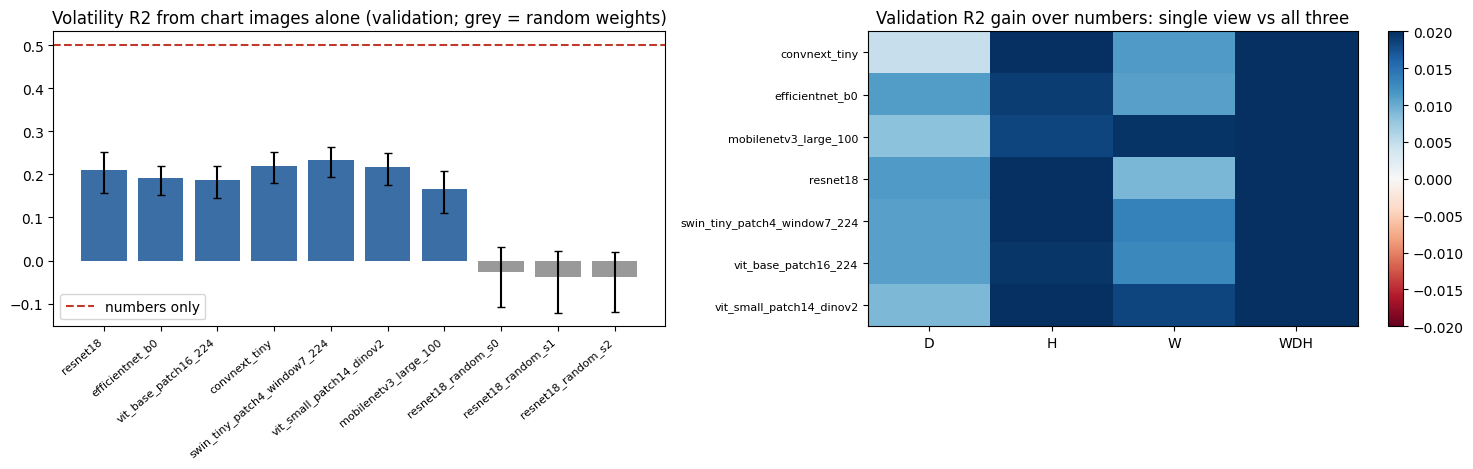

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...res/stage6_validation.png: 100%|##########|  107kB /  107kB            

Validating                    :           |   0%            


Frozen: /content/tfcv/frozen/frozen_config_quick.json (also on Drive and Hugging Face). Nothing below may change these choices.
Stage 6 done in 10s


In [13]:
# ==================================== STAGE 6: compare, select (pre-registered rule), calibrate, freeze ====================================
import matplotlib; import matplotlib.pyplot as plt
t0 = time.time()
METRIC_FN = {"V": T.r2, "O5": T.logloss, "D10": T.brier}
PREREG = {
    "selection": "Per target the best validation score wins (V: R2, O5: log loss, D10: Brier). A model that uses chart images is "
                 "chosen only if its validation gain over the best numbers-only model has a month-block 95% CI that excludes 0.",
    "H1": "On the test years, the best numbers+images model (chosen on validation among pretrained backbones) beats the numbers-only "
          "model: the 95% CI of delta-R2 (volatility) or delta-AUC (direction) lies above 0.",
    "H2": "On validation, image-only volatility R2 differs between at least two pretrained backbones (pairwise month-block "
          "bootstrap, Holm-adjusted p < 0.05).",
    "H3": "On the test years, accuracy of direction calls at 10% coverage (confidence threshold fixed on validation) exceeds "
          "accuracy at 100% coverage: the 95% CI of the difference lies above 0.",
    "no_trade": "NO TRADE unless direction is usable, confidence passes its validation threshold, and neither predicted volatility "
                "nor drawdown probability is in its validation top 20%. Direction is usable only if (a) on validation the Wilson "
                "lower bound of accuracy exceeds 0.5 at some coverage AND (b) on the test years the direction model's AUC 95% CI "
                "lies above 0.5 (validation alone is optimistic because it also chose the model).",
}
BOOT_VA = {t: T.MonthBoot(DATES[VA & OK[t]], N_BOOT, seed=SEED) for t in TARGETS}
SEL, VAL_SUMMARY = {}, {}
for t in TARGETS:
    tab = VAL_TABLES[t].copy()
    cand = tab[(tab.feature_set == "NUM") | tab.feature_set.str.startswith(("NUM+IMG:", "IMG:"))]
    cand = cand[~cand.feature_set.str.contains("random")]
    met, sign = PRIMARY[t]
    cand = cand.assign(score=sign * cand[met]).sort_values("score", ascending=False)
    best, num = cand.iloc[0], cand[cand.feature_set == "NUM"].iloc[0]
    y = Y[t][VA & OK[t]]
    key = lambda r: (t, r["feature_set"], r["head"])
    chosen, gate = num, None
    if best["feature_set"] != "NUM":
        ci, _ = BOOT_VA[t].diff(METRIC_FN[t], y, VAL_PRED[key(best)], VAL_PRED[key(num)])
        gate = dict(candidate=f"{best['feature_set']} / {best['head']}", delta=float(best[met] - num[met]), ci=ci)
        if (ci[0] > 0) if sign > 0 else (ci[1] < 0):
            chosen = best
    SEL[t] = dict(feature_set=chosen["feature_set"], head=chosen["head"], gate=gate,
                  fit={k: v for k, v in FITS[key(chosen)].items() if k not in ("model", "coef", "intercept")})
    # H1 comparison pair, fixed now: best numbers-only head and best numbers + all-three-views model (pretrained backbones)
    multi = cand[cand.feature_set.str.fullmatch(r"NUM\+IMG:[^:]+")]
    SEL[t]["h1_numbers"] = dict(feature_set="NUM", head=num["head"])
    SEL[t]["h1_images"] = dict(feature_set=multi.iloc[0]["feature_set"], head=multi.iloc[0]["head"]) if len(multi) else None
    VAL_SUMMARY[t] = {k: float(chosen[k]) for k in chosen.index if k in ("R2", "wmR2", "QLIKE", "MAE", "AUC", "logloss", "brier", "BSS", "ECE", "rankIC", "rankIC_t")}
    print(f"{t}: chosen {chosen['feature_set']} / {chosen['head']} ({met} {chosen[met]:.4f})"
          + (f"; best image model {gate['candidate']} delta {gate['delta']:+.4f}, CI [{gate['ci'][0]:+.4f}, {gate['ci'][1]:+.4f}]" if gate else ""))

# ---- H2 (validation): do pretrained backbones differ in image-only volatility R2?
yV, bV = Y["V"][VA & OK["V"]], BOOT_VA["V"]
img_r2 = {}
for b in NAMES:
    p = VAL_PRED[("V", f"IMG:{b}", "linear")]
    img_r2[b] = dict(R2=T.r2(yV, p), CI=bV.ci(T.r2, yV, p)[0])
pv = {}
pre = [b for b in NAMES if b in T.PRETRAINED]
for i, a in enumerate(pre):
    for b in pre[i + 1:]:
        _, draws = bV.diff(T.r2, yV, VAL_PRED[("V", f"IMG:{a}", "linear")], VAL_PRED[("V", f"IMG:{b}", "linear")])
        pv[f"{a} vs {b}"] = float(min(1.0, 2 * min((draws <= 0).mean(), (draws >= 0).mean())))
padj = T.holm(pv) if pv else {}
H2 = dict(supported=bool(any(p < 0.05 for p in padj.values())), n_pairs=len(pv),
          significant_pairs=[k for k, p in padj.items() if p < 0.05], image_only_R2=img_r2)
print(f"\nH2 (backbones differ, validation): {'SUPPORTED' if H2['supported'] else 'NOT SUPPORTED'} "
      f"- {len(H2['significant_pairs'])} of {len(pv)} pairs differ after Holm correction.")
print(pd.DataFrame({b: {"image-only R2": v["R2"], "lo": v["CI"][0], "hi": v["CI"][1]} for b, v in img_r2.items()}).T.round(3).to_string())

# ---- per-view (single timeframe) vs all three views, validation delta vs numbers only
rows = []
for b in pre:
    for t, met in (("V", "R2"), ("O5", "AUC")):
        tab = VAL_TABLES[t].set_index(["feature_set", "head"])
        base_ = tab.loc[("NUM", "linear"), met]
        for v in ("W", "D", "H", None):
            fs = f"NUM+IMG:{b}" + (f":{v}" if v else "")
            if (fs, "linear") in tab.index:
                rows.append(dict(backbone=b, target=t, views=v or "WDH", delta=float(tab.loc[(fs, "linear"), met] - base_)))
views_df = pd.DataFrame(rows)
save_df(views_df, "stage6_single_vs_multi_timeframe.csv")
print("\nValidation gain over numbers only (linear heads): single timeframe vs all three")
print(views_df.pivot_table(index=["target", "backbone"], columns="views", values="delta").round(4).to_string())

# ---- controls promised in the proposal: label shuffle (within each training month) and the naive majority-class baseline
rng_s = np.random.default_rng(SEED)
CONTROLS = {}
for t, fs in (("V", SEL["V"]["h1_images"]["feature_set"] if SEL["V"]["h1_images"] else "NUM"), ("O5", "NUM")):
    X = design(fs); mt, mv = TR & OK[t], VA & OK[t]
    ys = Y[t][mt].copy()
    if t == "V":                                          # volatility: shuffle across ALL training rows (a within-month shuffle
        ys = ys[rng_s.permutation(len(ys))]               # keeps month averages, which still teach a usable cross-sectional slope)
    else:                                                 # direction: within-month shuffle keeps the 50/50 base rate per period
        mon_tr, _ = T.month_codes(DATES[mt])
        for k in np.unique(mon_tr):
            ii = np.flatnonzero(mon_tr == k); ys[ii] = ys[rng_s.permutation(ii)]
    if t == "V":
        _, _, p = T.ridge_path(X[mt], ys, X[mv], [1000.0])[1000.0]
        yv = Y[t][mv]; c_, _ = T.month_codes(DATES[mv])
        CONTROLS["label_shuffle_V"] = dict(feature_set=fs, R2=T.r2(yv, p), wmR2=T.wm_r2(yv, p, c_))
    else:
        _, _, p = T.logit_path(X[mt], ys, X[mv], [0.01], device=DEVICE)[0.01]
        CONTROLS["label_shuffle_O5"] = dict(feature_set=fs, AUC=T.auc(Y[t][mv], p))
maj = int(BASE["O5"] >= 0.5)
CONTROLS["majority_class_accuracy_O5"] = float((Y["O5"][VA & OK["O5"]] == maj).mean())
print("\nControls (validation): " + "; ".join(f"{k}: " + ", ".join(f"{a} {b:.4f}" for a, b in v.items() if isinstance(b, float))
                                          if isinstance(v, dict) else f"{k}: {v:.4f}" for k, v in CONTROLS.items()))
print("   (with shuffled labels the pipeline must find nothing: volatility R2 at or below 0, within-month R2 near 0, direction AUC near 0.5)")

# ---- calibration, volatility residual band, NO TRADE rule (all from validation predictions)
def _vp(t):
    return VAL_PRED[(t, SEL[t]["feature_set"], SEL[t]["head"])]
CAL = {t: T.isotonic_arrays(_vp(t), Y[t][VA & OK[t]]) for t in ("O5", "D10")}
cal = lambda t, p: np.interp(p, CAL[t]["x"], CAL[t]["y"])
res = Y["V"][VA & OK["V"]] - _vp("V")
VRES = dict(res_q10=float(np.quantile(res, 0.10)), res_q50=float(np.quantile(res, 0.50)), res_q90=float(np.quantile(res, 0.90)), s2=float(np.var(res)))
pO5_va = cal("O5", _vp("O5")); yO5_va = Y["O5"][VA & OK["O5"]]
abst_va, THR = T.abstention_table(pO5_va, yO5_va)
usable = abst_va[(abst_va.coverage_target < 1) & (abst_va.wilson_lower > 0.5)]
cov_dir = float(usable.coverage_target.max()) if len(usable) else None
RULE = dict(vol_ann_q80=float(np.quantile(C.ann_vol(_vp("V")), 0.8)), p_dd10_q80=float(np.quantile(cal("D10", _vp("D10")), 0.8)),
            direction_usable=bool(len(usable)), coverage_for_direction=cov_dir,
            conf_threshold=float(THR[cov_dir]) if cov_dir else 0.5, thresholds_by_coverage={str(k): float(v) for k, v in THR.items()})
save_df(abst_va, "stage6_abstention_validation.csv")
print("\nAbstention on validation (calibrated direction probabilities):")
print(abst_va.round(4).to_string(index=False))
print(f"Direction usable: {RULE['direction_usable']} | NO TRADE risk thresholds: volatility >= {RULE['vol_ann_q80']:.1%} a year "
      f"or P(drawdown >= 10%) >= {RULE['p_dd10_q80']:.1%}")

# ---- figures
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
names_ = list(img_r2)
ax[0].bar(range(len(names_)), [img_r2[b]["R2"] for b in names_], yerr=np.array([[img_r2[b]["R2"] - img_r2[b]["CI"][0] for b in names_],
          [img_r2[b]["CI"][1] - img_r2[b]["R2"] for b in names_]]), color=["#3b6ea5" if b in T.PRETRAINED else "#999999" for b in names_], capsize=3)
ax[0].axhline(VAL_SUMMARY["V"].get("R2", np.nan) if SEL["V"]["feature_set"] == "NUM" else T.r2(yV, VAL_PRED[("V", "NUM", "linear")]), color="#c0392b", ls="--", label="numbers only")
ax[0].set_xticks(range(len(names_))); ax[0].set_xticklabels(names_, rotation=40, ha="right", fontsize=8)
ax[0].set_title("Volatility R2 from chart images alone (validation; grey = random weights)"); ax[0].legend()
vd = views_df[views_df.target == "V"].pivot_table(index="backbone", columns="views", values="delta")
im = ax[1].imshow(vd.values, cmap="RdBu", vmin=-0.02, vmax=0.02, aspect="auto")
ax[1].set_xticks(range(vd.shape[1])); ax[1].set_xticklabels(vd.columns); ax[1].set_yticks(range(vd.shape[0])); ax[1].set_yticklabels(vd.index, fontsize=8)
ax[1].set_title("Validation R2 gain over numbers: single view vs all three"); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); fpath = os.path.join(FIG, "stage6_validation.png"); plt.savefig(fpath, dpi=130); plt.show()
push(fpath, f"figures_{RUN_TAG}/stage6_validation.png")

# ---- freeze: everything the test and holdout stages are allowed to use
FROZEN = dict(run_tag=RUN_TAG, created_utc=dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), splits=SPLITS,
              holdout_start=HOLDOUT_START, n_rows={s: int(m.sum()) for s, m in (("train", TR), ("val", VA), ("test", TE))},
              split_ids_sha256=_sha(os.path.join(RES, f"split_ids_{RUN_TAG}.parquet")),
              selection=SEL, calibrators=CAL, volatility_residuals=VRES, rule=RULE, prereg=PREREG, H2=H2, controls=CONTROLS,
              n_configurations_tried=len(LEDGER), backbones=NAMES, pca_dim=PCA_DIM, seed=SEED)
FROZEN_PATH = os.path.join(WORK, "frozen", f"frozen_config_{RUN_TAG}.json")
json.dump(FROZEN, open(FROZEN_PATH, "w"), indent=1, default=float)
shutil.copy(FROZEN_PATH, os.path.join(DRIVE_DIR, os.path.basename(FROZEN_PATH)))
push(FROZEN_PATH, f"frozen/{os.path.basename(FROZEN_PATH)}")
print(f"\nFrozen: {FROZEN_PATH} (also on Drive and Hugging Face). Nothing below may change these choices.")
print(f"Stage 6 done in {time.time() - t0:.0f}s")

## Stage 7 - one honest test (2020-2022)
Refits the frozen choices on train + validation and reads the test years once.

In [14]:
# ==================================== STAGE 7: one honest test of the frozen choices (2020-2022) ====================================
t0 = time.time()
marker = os.path.join(WORK, "frozen", f"test_opened_{RUN_TAG}.json")
if os.path.exists(marker) and not os.environ.get("TFCV_TEST_REUSE_REASON"):
    raise RuntimeError(f"The {RUN_TAG} test set was already evaluated ({marker}). Re-running it would turn it into a tuning set. "
                       "If you must re-run (e.g. a crash), set os.environ['TFCV_TEST_REUSE_REASON'] = '<why>' and it is logged.")
FZ = json.load(open(FROZEN_PATH))                         # only frozen choices are used below
SELF = FZ["selection"]
cal = lambda t, p: np.interp(p, FZ["calibrators"][t]["x"], FZ["calibrators"][t]["y"])
FIT_TV = TR | VA


def refit(t, fs, head, fit_mask, pred_mask):
    """Refit a frozen configuration on fit_mask rows (same hyper-parameters) and predict pred_mask rows."""
    X = design(fs); mf = fit_mask & OK[t]; f = FITS[(t, fs, head)]
    if head == "linear":
        if TARGETS[t] == "reg":
            w, b, p = T.ridge_path(X[mf], Y[t][mf], X[pred_mask], [f["param"]])[f["param"]]
        else:
            w, b, p = T.logit_path(X[mf], Y[t][mf], X[pred_mask], [f["param"]], device=DEVICE)[f["param"]]
        return dict(head="linear", coef=w, intercept=float(b)), p
    m, _, _ = T.tree_fit(X[mf], Y[t][mf], None, None, TARGETS[t], f["cfg"], gpu=(DEVICE == "cuda"), seed=SEED, n_estimators=f["n_estimators"])
    return dict(head="tree", model=m), T.tree_predict(m, X[pred_mask], TARGETS[t])


MTE = {t: TE & OK[t] for t in TARGETS}
BOOT_TE = {t: T.MonthBoot(DATES[MTE[t]], N_BOOT, seed=SEED) for t in TARGETS}
FINAL, TEST_PRED, TEST_SUMMARY = {}, {}, {}
for t in TARGETS:
    s = SELF[t]
    FINAL[t], p = refit(t, s["feature_set"], s["head"], FIT_TV, MTE[t])
    if TARGETS[t] == "clf":
        p = cal(t, p)
    TEST_PRED[t] = p
    y = Y[t][MTE[t]]; bt = BOOT_TE[t]
    met = eval_target(t, y, p, DATES[MTE[t]], s2=FZ["volatility_residuals"]["s2"] if t == "V" else None,
                      xret=XRET[MTE[t]] if t == "O5" else None, base=BASE.get(t))
    if t == "V":
        met["R2_CI"] = bt.ci(T.r2, y, p)[0]; met["wmR2_CI"] = bt.ci(T.wm_r2, y, p, uses_months=True)[0]
    else:
        met["AUC_CI"] = bt.ci(T.auc, y, p)[0]
        met["BSS_CI"] = bt.ci(lambda yy, pp: 1 - T.brier(yy, pp) / T.brier(yy, np.full(len(yy), BASE[t])), y, p)[0]
    TEST_SUMMARY[t] = met
    print(f"{t} ({s['feature_set']} / {s['head']}): " + ", ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in met.items()))

# ---- H1: numbers + all three chart views vs numbers only, on the test years (pre-registered pair)
H1 = {}
for t, fn, nm in (("V", T.r2, "R2"), ("O5", T.auc, "AUC")):
    pn_, pi_ = SELF[t]["h1_numbers"], SELF[t]["h1_images"]
    if pi_ is None:
        continue
    _, p_num = refit(t, pn_["feature_set"], pn_["head"], FIT_TV, MTE[t])
    _, p_img = refit(t, pi_["feature_set"], pi_["head"], FIT_TV, MTE[t])
    y = Y[t][MTE[t]]
    ci, _ = BOOT_TE[t].diff(fn, y, p_img, p_num)
    H1[t] = dict(images_model=f"{pi_['feature_set']} / {pi_['head']}", numbers_model=f"NUM / {pn_['head']}",
                 metric=nm, numbers=fn(y, p_num), images=fn(y, p_img), delta=fn(y, p_img) - fn(y, p_num), CI=ci)
H1_supported = bool(any(v["CI"][0] > 0 for v in H1.values()))
print(f"\nH1 (three timeframes of chart images add to the numbers, test years): {'SUPPORTED' if H1_supported else 'NOT SUPPORTED'}")
for t, v in H1.items():
    print(f"   {t}: {v['images_model']} vs {v['numbers_model']}: delta {v['metric']} {v['delta']:+.4f}, 95% CI [{v['CI'][0]:+.4f}, {v['CI'][1]:+.4f}]")

# ---- H3: does abstention improve accepted direction calls? (thresholds fixed on validation)
thr10 = FZ["rule"]["thresholds_by_coverage"]["0.1"]
yo, po = Y["O5"][MTE["O5"]].astype(int), TEST_PRED["O5"]
abst_te, _ = T.abstention_table(po, yo, thresholds={float(k): v for k, v in FZ["rule"]["thresholds_by_coverage"].items()})


def _gain(yy, pp):
    keep = np.abs(pp - 0.5) >= thr10
    return (((pp[keep] > 0.5) == yy[keep]).mean() if keep.any() else np.nan) - ((pp > 0.5) == yy).mean()


h3_ci, _ = BOOT_TE["O5"].ci(_gain, yo, po)
H3 = dict(gain_10pct_vs_all=float(_gain(yo, po)), CI=h3_ci, supported=bool(h3_ci[0] > 0), table=abst_te.to_dict("records"))
print(f"H3 (abstention raises accuracy of accepted calls, test years): {'SUPPORTED' if H3['supported'] else 'NOT SUPPORTED'} "
      f"- accuracy gain at 10% coverage {H3['gain_10pct_vs_all']:+.4f}, 95% CI [{h3_ci[0]:+.4f}, {h3_ci[1]:+.4f}]")
print(abst_te.round(4).to_string(index=False))

# ---- NO TRADE rule on the test years: what does the risk flag separate?
common = MTE["V"] & MTE["O5"] & MTE["D10"]
def _on(t):                                            # test predictions restricted to rows valid for all targets
    return TEST_PRED[t][common[MTE[t]]]
vol_hat, pdd = C.ann_vol(_on("V")), _on("D10")
risk = (vol_hat >= FZ["rule"]["vol_ann_q80"]) | (pdd >= FZ["rule"]["p_dd10_q80"])
real_vol, real_dd = C.ann_vol(Y["V"][common]), Y["D10"][common]
NT = dict(share_flagged=float(risk.mean()),
          realised_vol_flagged=float(real_vol[risk].mean()), realised_vol_other=float(real_vol[~risk].mean()),
          dd10_rate_flagged=float(real_dd[risk].mean()), dd10_rate_other=float(real_dd[~risk].mean()))
if FZ["rule"]["direction_usable"]:
    callm = (~risk) & (np.abs(_on("O5") - 0.5) >= FZ["rule"]["conf_threshold"])
    NT["direction_calls_share"] = float(callm.mean())
    NT["direction_calls_accuracy"] = float(((_on("O5")[callm] > 0.5) == Y["O5"][common][callm]).mean()) if callm.any() else None
print(f"\nNO TRADE risk flag on the test years: flags {NT['share_flagged']:.1%} of cases; realised volatility "
      f"{NT['realised_vol_flagged']:.1%} vs {NT['realised_vol_other']:.1%} a year; 10% drawdowns {NT['dd10_rate_flagged']:.1%} vs {NT['dd10_rate_other']:.1%}")

# ---- survivorship sensitivity: refit without the 2001-2009 cache (the cache most exposed to survivorship)
SURV = {}
no_early = FIT_TV & (df["src"].values != "cache_2001_2009")
for t in TARGETS:
    s = SELF[t]
    _, p2 = refit(t, s["feature_set"], s["head"], no_early, MTE[t])
    p2 = cal(t, p2) if TARGETS[t] == "clf" else p2
    y = Y[t][MTE[t]]
    SURV[t] = dict(with_2001_2009=T.r2(y, TEST_PRED[t]) if t == "V" else T.auc(y, TEST_PRED[t]),
                   without_2001_2009=T.r2(y, p2) if t == "V" else T.auc(y, p2), metric="R2" if t == "V" else "AUC")
print("Survivorship sensitivity (test metric with / without the 2001-2009 rows in training):",
      {t: f"{v['metric']} {v['with_2001_2009']:.4f} / {v['without_2001_2009']:.4f}" for t, v in SURV.items()})

# ---- deployment rule = frozen rule + the pre-registered test-year check on direction (part b of PREREG['no_trade'])
RULE_DEPLOY = dict(FZ["rule"])
RULE_DEPLOY["direction_usable"] = bool(FZ["rule"]["direction_usable"] and TEST_SUMMARY["O5"]["AUC_CI"][0] > 0.5)
print(f"Direction shown as a call on the dashboard: {RULE_DEPLOY['direction_usable']} "
      f"(validation check {FZ['rule']['direction_usable']}, test AUC CI {TEST_SUMMARY['O5']['AUC_CI'][0]:.3f}-{TEST_SUMMARY['O5']['AUC_CI'][1]:.3f})")
TEST_RESULTS = dict(summary=TEST_SUMMARY, H1=H1, H1_supported=H1_supported, H3=H3, no_trade=NT, survivorship=SURV,
                    rule_deploy=RULE_DEPLOY, n_test_rows={t: int(MTE[t].sum()) for t in TARGETS})
tpath = os.path.join(RES, "stage7_test_results.json")
json.dump(TEST_RESULTS, open(tpath, "w"), indent=1, default=float)
push(tpath, f"results_{RUN_TAG}/stage7_test_results.json")
pred_df = df.loc[MTE["V"], ["sample_id", "ticker", "date"]].assign(pred_logrv20=TEST_PRED["V"])
ppath = os.path.join(RES, "stage7_test_predictions.parquet"); pred_df.to_parquet(ppath, index=False)
push(ppath, f"results_{RUN_TAG}/stage7_test_predictions.parquet")
json.dump(dict(utc=dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), reuse_reason=os.environ.get("TFCV_TEST_REUSE_REASON", "")),
          open(marker, "w"))
push(marker, f"frozen/{os.path.basename(marker)}")
print(f"\nStage 7 done in {time.time() - t0:.0f}s")

V (NUM+IMG:swin_tiny_patch4_window7_224 / tree): n 4358, R2 0.4958, wmR2 0.5500, QLIKE 0.5563, MAE 0.2677, R2_CI [0.2585966153273082, 0.6367416606473139], wmR2_CI [0.4478944126459183, 0.6289990762511045]
O5 (NUM / tree): n 4358, AUC 0.5098, logloss 0.6939, brier 0.2504, ECE 0.0082, BSS -0.0017, rankIC nan, rankIC_t nan, AUC_CI [0.49761910596803194, 0.5219681478244592], BSS_CI [-0.005426096539019515, 0.0018829334368642696]
D10 (NUM+IMG:vit_small_patch14_dinov2 / tree): n 4358, AUC 0.6559, logloss 0.6361, brier 0.1977, ECE 0.0581, BSS 0.0617, AUC_CI [0.5948410262702167, 0.7049208442551157], BSS_CI [0.018290570192883476, 0.09801966992608932]

H1 (three timeframes of chart images add to the numbers, test years): NOT SUPPORTED
   V: NUM+IMG:swin_tiny_patch4_window7_224 / tree vs NUM / tree: delta R2 +0.0039, 95% CI [-0.0044, +0.0123]
   O5: NUM+IMG:mobilenetv3_large_100 / tree vs NUM / tree: delta AUC -0.0071, 95% CI [-0.0261, +0.0121]
H3 (abstention raises accuracy of accepted calls, test 

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ..._test_predictions.parquet: 100%|##########| 68.5kB / 68.5kB            

Validating                    :           |   0%            


Stage 7 done in 19s


## Stage 8 - model bundle and parity checks
The bundle must reproduce the notebook's test predictions, and the dashboard's input code must reproduce the training inputs exactly.

In [15]:
# ==================================== STAGE 8: the deployable model bundle + two parity checks + model card ====================================
t0 = time.time()
B_DIR = os.path.join(WORK, "bundle")
shutil.rmtree(B_DIR, ignore_errors=True); os.makedirs(B_DIR)
arrays = {"num_fill": num_fill, "num_mean": num_mean, "num_std": num_std}
tcfg, need = {}, {}
for t in TARGETS:
    s, mdl = SELF[t], FINAL[t]
    spec = dict(task=TARGETS[t], feature_set=s["feature_set"], params=s["fit"])
    if mdl["head"] == "linear":
        spec["head"] = "linear"; arrays[f"coef|{t}"] = mdl["coef"]; arrays[f"intercept|{t}"] = np.array(mdl["intercept"])
    else:
        fname = f"{t}.json" if T.tree_backend() == "xgb" else f"{t}.txt"
        spec["head"] = T.tree_save(mdl["model"], os.path.join(B_DIR, fname)); spec["file"] = fname
    if t == "V":
        spec.update(FZ["volatility_residuals"])
    else:
        spec["calibrator"] = FZ["calibrators"][t]
    tcfg[t] = spec
    use_num, b, views = C.Bundle.parse_fs(s["feature_set"])
    if b is not None:
        need.setdefault(b, set()).update(views)
        for v in views:
            mz = np.load(os.path.join(PCA_DIR, f"{b}__{v}_meta.npz"))
            arrays[f"pca_mean|{b}|{v}"], arrays[f"pca_comp|{b}|{v}"] = mz["mean"], mz["comp"]
        _, mu_, sd_ = img_matrix(b, views)
        arrays[f"img_mean|{b}|{''.join(views)}"], arrays[f"img_std|{b}|{''.join(views)}"] = mu_, sd_
recs = json.load(open(os.path.join(RES, "backbones.json")))
versions = {"numpy": np.__version__, "pandas": pd.__version__, "torch": torch.__version__}
for mod in ("xgboost", "lightgbm", "timm", "sklearn"):
    try:
        versions[mod] = __import__(mod).__version__
    except Exception:
        pass
BUNDLE_CFG = dict(version="tfcv-1", run_tag=RUN_TAG, created_utc=dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
                  features=FEATS, img_clip=10.0, views=list(T.VIEWS), targets=tcfg,
                  backbones={b: recs[b] for b in need}, rule=RULE_DEPLOY, base_rates=BASE, splits=SPLITS,
                  metrics=dict(val=VAL_SUMMARY, test=TEST_SUMMARY), hypotheses=dict(H1_supported=H1_supported, H2=FZ["H2"]["supported"], H3=H3["supported"]),
                  prereg=FZ["prereg"], frozen_config_sha256=_sha(FROZEN_PATH), versions=versions,
                  data=dict(universe=len(all_tickers), tickers_used=int(df["ticker"].nunique()), rows=len(df)))
json.dump(BUNDLE_CFG, open(os.path.join(B_DIR, "config.json"), "w"), indent=1, default=float)
np.savez(os.path.join(B_DIR, "arrays.npz"), **{k: np.asarray(v) for k, v in arrays.items()})

# ---- parity 1: the saved bundle reproduces the notebook's own test predictions (same rows, raw inputs)
BD = C.Bundle(B_DIR)
common = MTE["V"] & MTE["O5"] & MTE["D10"]
sel_rows = np.flatnonzero(common)[:3000]
emb = {b: {v: T.assemble(EMB_DIR, f"{b}|{v}", df["sample_id"].values[sel_rows]) for v in T.VIEWS} for b in need}
pb = BD.predict_matrix(Xraw[sel_rows], emb)
pos = {t: np.searchsorted(np.flatnonzero(MTE[t]), sel_rows) for t in TARGETS}
dif = {"V": np.abs(pb["logrv20"] - TEST_PRED["V"][pos["V"]]), "O5": np.abs(pb["p_out5"] - TEST_PRED["O5"][pos["O5"]]),
       "D10": np.abs(pb["p_dd10"] - TEST_PRED["D10"][pos["D10"]])}
print("Bundle vs notebook test predictions:", {k: f"median {np.median(v):.1e}, max {v.max():.1e}, rows > 1e-3: {(v > 1e-3).mean():.2%}" for k, v in dif.items()})
# float32 rounding can flip a tree split on a handful of rows; anything systematic fails here
assert all(np.median(v) < 1e-4 and (v > 1e-3).mean() < 0.005 for v in dif.values()), "the saved bundle does not reproduce the notebook predictions"

# ---- parity 2: dashboard input pipeline (raw bars -> features + charts) equals the training inputs
if os.path.isdir(f"{DST}/final/1day"):
    import pandas_market_calendars as mcal
    sch = mcal.get_calendar("XNYS").schedule("2000-12-01", "2026-12-31")
    early = set(pd.DatetimeIndex(sch.index[sch.market_close.dt.tz_convert("America/New_York").dt.hour < 16]).normalize())
    pick = df[TE].sample(min(40, int(TE.sum())), random_state=SEED)
    fbad = tbad = 0
    for _, r in pick.iterrows():
        d0 = pd.read_parquet(f"{DST}/final/1day/{r.ticker}.parquet")[["date", "open", "high", "low", "close", "volume"]]
        h0 = C.rth_only(pd.read_parquet(f"{DST}/final/1hour/{r.ticker}.parquet"), early)
        k = int(np.searchsorted(d0["date"].values.astype("datetime64[ns]"), np.datetime64(r.date, "ns")))
        f_ = C.features_at(d0, k); ref = r[FEATS].to_numpy(float)
        fbad += int(not np.all(np.isclose(f_, ref, rtol=1e-7, atol=1e-9) | (np.isnan(f_) & np.isnan(ref))))
        tr_ = C.render_at(d0, h0, k); ref_img = st.triplet(r.sample_id)
        tbad += int(not all(np.array_equal(tr_[v], ref_img[v]) for v in T.VIEWS))
    print(f"Dashboard input pipeline vs training inputs on {len(pick)} test rows: feature mismatches {fbad}, chart mismatches {tbad}")
    assert fbad == 0 and tbad == 0, "the dashboard would not see what the model was trained on"

# ---- model card (only computed values)
def _fmt(d):
    return ", ".join(f"{k} {v:.3f}" for k, v in d.items() if isinstance(v, float))
card = [f"# TriFrame CV model bundle ({RUN_TAG} run)", "",
        "Frozen models behind the *Computer Vision with Deep Learning Project Dashboard*. Private: data and weights are not licensed for publication.", "",
        "| Target | Inputs | Head | Test metrics (2020-2022) |", "|---|---|---|---|"]
for t in TARGETS:
    card.append(f"| {TARGET_NAME[t]} | {tcfg[t]['feature_set']} | {tcfg[t]['head']} | {_fmt(TEST_SUMMARY[t])} |")
card += ["", f"H1 (images add to numbers, test): {'supported' if H1_supported else 'not supported'}; "
         f"H2 (backbones differ, validation): {'supported' if FZ['H2']['supported'] else 'not supported'}; "
         f"H3 (abstention helps, test): {'supported' if H3['supported'] else 'not supported'}.", "",
         f"Splits: {SPLITS}. Holdout from {HOLDOUT_START} (see Stage 10 results if run). Configurations tried: {FZ['n_configurations_tried']}.",
         "Limits: 979 survivor US stocks, one data vendor; not investment advice."]
open(os.path.join(B_DIR, "README.md"), "w").write("\n".join(card))
push(B_DIR, "", repo_id=MODEL_REPO, repo_type="model", msg=f"bundle {RUN_TAG}")
print(f"Bundle written to {B_DIR}" + (f" and pushed to {MODEL_REPO} (private)" if UPLOAD else " (upload off)")
      + f". Backbones needed at inference: {sorted(need) or 'none'}")
print(f"Stage 8 done in {time.time() - t0:.0f}s")

Bundle vs notebook test predictions: {'V': 'median 1.2e-06, max 6.4e-06, rows > 1e-3: 0.00%', 'O5': 'median 0.0e+00, max 1.2e-05, rows > 1e-3: 0.00%', 'D10': 'median 0.0e+00, max 5.7e-05, rows > 1e-3: 0.00%'}
Bundle written to /content/tfcv/bundle and pushed to KrishnaHarshaTangirala/triframe-cv-model (private). Backbones needed at inference: ['swin_tiny_patch4_window7_224', 'vit_small_patch14_dinov2']
Stage 8 done in 10s


## Stage 9 - dashboard and website page
Pushes the Gradio app to a Hugging Face Space and writes the HTML block for a new page on krishnaharsha.com.

In [16]:
# ==================================== STAGE 9: the dashboard (Hugging Face Space) and the krishnaharsha.com page ====================================
SPACE_DIR = os.path.join(WORK, "space")
shutil.rmtree(SPACE_DIR, ignore_errors=True); os.makedirs(SPACE_DIR)
for f in ("tf_render.py", "feat_visible.py"):
    shutil.copy(os.path.join(DST, "scripts", f), SPACE_DIR)
for f in ("tfcv_core.py", "screen_reader.py", "app.py"):
    shutil.copy(os.path.join(WORK, f), SPACE_DIR)
req = [f"gradio=={GRADIO_VERSION}", "numpy", "pandas", "pillow", "huggingface_hub", "yfinance", "rapidocr_onnxruntime==1.4.4", "onnxruntime"]
heads = {s["head"] for s in BUNDLE_CFG["targets"].values()}
if "xgb" in heads:
    req.append("xgboost-cpu")                                 # reads model JSON written by the same or older xgboost
if "lgbm" in heads:
    req.append("lightgbm")
if BUNDLE_CFG["backbones"]:                                   # only if a chosen model uses chart images
    req += ["--extra-index-url https://download.pytorch.org/whl/cpu", "torch", f"timm=={BUNDLE_CFG['versions'].get('timm', '')}".rstrip("=")]
open(os.path.join(SPACE_DIR, "requirements.txt"), "w").write("\n".join(req) + "\n")
open(os.path.join(SPACE_DIR, "packages.txt"), "w").write("libgl1\nlibglib2.0-0\n")
open(os.path.join(SPACE_DIR, "README.md"), "w").write(
    "---\ntitle: Computer Vision with Deep Learning Project Dashboard\nemoji: 📈\ncolorFrom: gray\ncolorTo: blue\nsdk: gradio\n"
    f"sdk_version: {GRADIO_VERSION}\npython_version: \"3.11\"\napp_file: app.py\npinned: false\n"
    "short_description: Three chart screenshots in; volatility, drawdown risk, direction and NO TRADE out.\n---\n\n"
    "TriFrame dashboard. The model bundle is loaded from a private model repository at start-up.\n")
SPACE_URL = f"https://{SPACE_REPO.replace('/', '-').replace('_', '-').replace('.', '-').lower()}.hf.space"
if UPLOAD:
    try:
        api.create_repo(SPACE_REPO, repo_type="space", space_sdk="gradio", private=SPACE_PRIVATE, exist_ok=True)
        api.upload_folder(folder_path=SPACE_DIR, repo_id=SPACE_REPO, repo_type="space", commit_message=f"dashboard ({RUN_TAG} bundle)")
        api.add_space_variable(SPACE_REPO, "MODEL_REPO", MODEL_REPO)
        if HF_READ_TOKEN:
            api.add_space_secret(SPACE_REPO, "HF_TOKEN", HF_READ_TOKEN)
            print("Space secret HF_TOKEN set from the Colab secret HF_READ_TOKEN.")
        else:
            print("ACTION NEEDED: in the Space settings add a secret HF_TOKEN = a READ-only token (so it can load the private model).")
        print(f"Space pushed: https://huggingface.co/spaces/{SPACE_REPO}  (app URL {SPACE_URL}; first build takes 5-10 min)")
    except Exception as e:
        FAILED_UPLOADS.append((SPACE_DIR, "", SPACE_REPO, "space")); print("Space upload failed:", e)

# ---- the page for krishnaharsha.com (paste into a Custom HTML / Embed block, or upload as its own page)
tm = BUNDLE_CFG["metrics"]["test"]
page = f"""<!-- Computer Vision with Deep Learning Project Dashboard: paste into a Custom HTML / Embed code block -->
<section style="max-width:1100px;margin:0 auto;padding:24px 16px;font-family:system-ui,Segoe UI,Arial,sans-serif;color:#1d2533">
  <h1 style="font-size:32px;margin:0 0 12px">Computer Vision with Deep Learning Project Dashboard</h1>
  <p style="font-size:16px;line-height:1.6">TriFrame tests whether weekly, daily and hourly chart images add information about a US stock's
  next-20-day volatility, drawdown risk and 5-day relative direction beyond plain numbers from the same price history. Seven frozen,
  ImageNet-pretrained vision models were compared with a numerical baseline on 979 US stocks, with chronological training,
  validation and test periods and a sealed final holdout.</p>
  <p style="font-size:16px;line-height:1.6"><strong>How to use:</strong> upload three TradingView screenshots of one stock (1W, 1D and 1H).
  The app reads the ticker and the last bar of each picture, checks them against market data, rebuilds the exact inputs the model
  was trained on and returns expected volatility, the chance of a 10% drawdown, the chance of beating the median stock over five
  days, and a NO TRADE decision (the default).</p>
  <p style="font-size:14px;color:#555">Test-period results (2020-2022): volatility R&sup2; {tm['V'].get('R2', float('nan')):.2f};
  drawdown AUC {tm['D10'].get('AUC', float('nan')):.2f}; direction AUC {tm['O5'].get('AUC', float('nan')):.3f}.
  Research output, not investment advice.</p>
  <iframe src="{SPACE_URL}" title="TriFrame dashboard" style="width:100%;height:1700px;border:0;border-radius:8px" loading="lazy"></iframe>
</section>
"""
WEB = os.path.join(WORK, "web", "krishnaharsha_cv_dashboard.html")
open(WEB, "w").write(page)
shutil.copy(WEB, os.path.join(DRIVE_DIR, os.path.basename(WEB)))
push(WEB, "web/krishnaharsha_cv_dashboard.html")
print(f"Website snippet: {WEB} (also on Drive: {DRIVE_DIR}).")

Space upload failed: Client error '402 Payment Required' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6ad677b4-5c8d762f79a2a783522e6e1e;fb645f75-acc8-47d1-8e0f-917cacafc1e8)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription. Subscribe at https://huggingface.co/pro
Website snippet: /content/tfcv/web/krishnaharsha_cv_dashboard.html (also on Drive: /content/drive/MyDrive/triframe_cv).


## Stage 10 - holdout (owner only, once)
Leave `RUN_HOLDOUT = False` until you are satisfied with the frozen config. Opening it is logged and single-use.

In [17]:
# ==================================== STAGE 10 (owner only, once): the sealed holdout 2023-01-03 onward ====================================
# Run this cell only when the frozen config is final. It opens the holdout through holdout_guard (single use, hash-chained log).
# 1) Look at the frozen config:  print(open(FROZEN_PATH).read())
# 2) Compute its SHA-256 yourself:  !sha256sum {FROZEN_PATH}
# 3) Set RUN_HOLDOUT = True below and run; paste the SHA-256 when asked (it is not stored in the notebook).
RUN_HOLDOUT = False
if RUN_HOLDOUT:
    from getpass import getpass
    os.environ["TRIFRAME_HOLDOUT_CONFIG"] = FROZEN_PATH
    os.environ["TRIFRAME_HOLDOUT_UNLOCK"] = getpass("SHA-256 of the frozen config (owner): ").strip()
    t0 = time.time()
    st_h = ImageStore(who=f"tfcv_holdout_{RUN_TAG}", root=DST + "/", allow_holdout=True)      # logged, single use per config
    push(os.path.join(GOV, "holdout_access_log.csv"), "governance/holdout_access_log.csv")
    idx_h = st_h.index()
    hd = st_h.join_features(idx_h).merge(st_h.derived_labels()[["sample_id", "xret5_med", "dd20_le_10"]], on="sample_id", how="left")
    hd = hd[(pd.to_datetime(hd["date"]) >= HOLDOUT_START) & hd["ticker"].isin(df["ticker"].unique())]
    hd = hd.sort_values(["ticker", "date"]).reset_index(drop=True)
    need_b = BD.needed_backbones()
    emb_h = {}
    if need_b:
        HOLD_DIR = os.path.join(WORK, f"emb_holdout_{RUN_TAG}")
        rows_h = st_h._idx.set_index("sample_id").loc[hd["sample_id"].values].reset_index()
        T.extract_embeddings(st_h, rows_h, need_b, HOLD_DIR, DEVICE, chunk_tickers=CHUNK_TICKERS, batch=BATCH, factory=globals().get("FACTORY"))
        emb_h = {b: {v: T.assemble(HOLD_DIR, f"{b}|{v}", hd["sample_id"].values) for v in T.VIEWS} for b in need_b}
    ph = BD.predict_matrix(hd[FEATS].to_numpy(float), emb_h)                 # the deployed bundle, nothing refitted
    HOLD = {}
    for t, col, key in (("V", "logrv20", "logrv20"), ("O5", "y_out5", "p_out5"), ("D10", "dd20_le_10", "p_dd10")):
        y = hd[col].to_numpy(float); ok = np.isfinite(y)
        for part, m in (("all", ok), ("to_2026-02-28", ok & (pd.to_datetime(hd["date"]) <= "2026-02-28").values),
                        ("after_2026-02-28", ok & (pd.to_datetime(hd["date"]) > "2026-02-28").values)):
            if m.sum() < 50:
                continue
            res_ = eval_target(t, y[m], ph[key][m], hd["date"].values[m], s2=FZ["volatility_residuals"]["s2"] if t == "V" else None,
                               xret=hd["xret5_med"].to_numpy(float)[m] if t == "O5" else None, base=BASE.get(t))
            bt = T.MonthBoot(hd["date"].values[m], N_BOOT, seed=SEED)
            res_["CI"] = bt.ci(T.r2 if t == "V" else T.auc, y[m], ph[key][m])[0]
            HOLD[f"{t}|{part}"] = res_
            print(f"{t} {part}: " + ", ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in res_.items()))
    hpath = os.path.join(RES, "stage10_holdout_results.json")
    json.dump(dict(results=HOLD, rows=len(hd), utc=dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")), open(hpath, "w"), indent=1, default=float)
    push(hpath, f"results_{RUN_TAG}/stage10_holdout_results.json")
    BUNDLE_CFG["metrics"]["holdout"] = HOLD
    json.dump(BUNDLE_CFG, open(os.path.join(B_DIR, "config.json"), "w"), indent=1, default=float)
    push(os.path.join(B_DIR, "config.json"), "config.json", repo_id=MODEL_REPO, repo_type="model", msg="add holdout results")
    print(f"Holdout evaluated once in {time.time() - t0:.0f}s and logged in {GOV}.")
else:
    print("Holdout not opened (RUN_HOLDOUT = False). This is the default until the owner decides the frozen config is final.")

Holdout not opened (RUN_HOLDOUT = False). This is the default until the owner decides the frozen config is final.


In [19]:
# ==================================== STAGE 10: Run the Sealed Holdout (2023+) ====================================
RUN_HOLDOUT = True

if RUN_HOLDOUT:
    t0 = time.time()
    if not os.path.isfile(FROZEN_PATH):
        raise FileNotFoundError(f"Frozen config not found at {FROZEN_PATH}.")

    # Auto-compute SHA-256 unlock key
    with open(FROZEN_PATH, "rb") as f:
        config_sha256 = hashlib.sha256(f.read()).hexdigest()
    print(f"Unlocking with Config SHA-256: {config_sha256}")

    os.environ["TRIFRAME_HOLDOUT_CONFIG"] = FROZEN_PATH
    os.environ["TRIFRAME_HOLDOUT_UNLOCK"] = config_sha256

    # Open sealed dataset
    st_h = ImageStore(who=f"tfcv_holdout_{RUN_TAG}", root=DST + "/", allow_holdout=True)
    push(os.path.join(GOV, "holdout_access_log.csv"), "governance/holdout_access_log.csv")

    idx_h = st_h.index()
    hd = st_h.join_features(idx_h).merge(
        st_h.derived_labels()[["sample_id", "xret5_med", "dd20_le_10"]],
        on="sample_id",
        how="left"
    )
    hd = hd[(pd.to_datetime(hd["date"]) >= HOLDOUT_START) & hd["ticker"].isin(df["ticker"].unique())]
    hd = hd.sort_values(["ticker", "date"]).reset_index(drop=True)
    print(f"Holdout rows: {len(hd):,} ({hd['ticker'].nunique()} tickers)")

    need_b = BD.needed_backbones()
    emb_h = {}
    if need_b:
        print(f"Extracting holdout embeddings for: {need_b}...")
        HOLD_DIR = os.path.join(WORK, f"emb_holdout_{RUN_TAG}")
        rows_h = st_h._idx.set_index("sample_id").loc[hd["sample_id"].values].reset_index()
        T.extract_embeddings(st_h, rows_h, need_b, HOLD_DIR, DEVICE,
                             chunk_tickers=CHUNK_TICKERS, batch=BATCH, factory=globals().get("FACTORY"))
        emb_h = {b: {v: T.assemble(HOLD_DIR, f"{b}|{v}", hd["sample_id"].values) for v in T.VIEWS} for b in need_b}

    ph = BD.predict_matrix(hd[FEATS].to_numpy(float), emb_h)

    HOLD = {}
    for t, col, key in (("V", "logrv20", "logrv20"), ("O5", "y_out5", "p_out5"), ("D10", "dd20_le_10", "p_dd10")):
        y = hd[col].to_numpy(float)
        ok = np.isfinite(y)
        for part, m in (("all", ok),
                        ("to_2026-02-28", ok & (pd.to_datetime(hd["date"]) <= "2026-02-28").values),
                        ("after_2026-02-28", ok & (pd.to_datetime(hd["date"]) > "2026-02-28").values)):
            if m.sum() < 50:
                continue
            res_ = eval_target(t, y[m], ph[key][m], hd["date"].values[m],
                               s2=FZ["volatility_residuals"]["s2"] if t == "V" else None,
                               xret=hd["xret5_med"].to_numpy(float)[m] if t == "O5" else None,
                               base=BASE.get(t))
            bt = T.MonthBoot(hd["date"].values[m], N_BOOT, seed=SEED)
            res_["CI"] = bt.ci(T.r2 if t == "V" else T.auc, y[m], ph[key][m])[0]
            HOLD[f"{t}|{part}"] = res_
            print(f"Holdout [{t} - {part}]: " + ", ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in res_.items()))

    hpath = os.path.join(RES, "stage10_holdout_results.json")
    json.dump(dict(results=HOLD, rows=len(hd), utc=dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")),
              open(hpath, "w"), indent=1, default=float)
    push(hpath, f"results_{RUN_TAG}/stage10_holdout_results.json")

    BUNDLE_CFG["metrics"]["holdout"] = HOLD
    json.dump(BUNDLE_CFG, open(os.path.join(B_DIR, "config.json"), "w"), indent=1, default=float)
    push(os.path.join(B_DIR, "config.json"), "config.json", repo_id=MODEL_REPO, repo_type="model", msg="add holdout results")

    print(f"\n[DONE] Stage 10 holdout evaluated in {time.time() - t0:.0f}s.")

Unlocking with Config SHA-256: d0d6c71ae321247bf179a0c1726e39340f12871a5de4baff3e9226ecd328453a
Holdout rows: 5,612 (60 tickers)
Extracting holdout embeddings for: ['swin_tiny_patch4_window7_224', 'vit_small_patch14_dinov2']...
   chunk 1/2: 3,742 rows, 603 rows/s this session
   chunk 2/2: 1,870 rows, 605 rows/s this session
Holdout [V - all]: n 5524, R2 0.5497, wmR2 0.5769, QLIKE 0.2822, MAE 0.2466, CI [0.5080085952115444, 0.5877877908953006]
Holdout [V - to_2026-02-28]: n 4712, R2 0.5353, wmR2 0.5681, QLIKE 0.2987, MAE 0.2506, CI [0.4908554428360483, 0.5777018988069352]
Holdout [V - after_2026-02-28]: n 812, R2 0.6135, wmR2 0.6290, QLIKE 0.1868, MAE 0.2232, CI [0.541570181046772, 0.6676802957202503]
Holdout [O5 - all]: n 5612, AUC 0.4900, logloss 0.6959, brier 0.2513, ECE 0.0235, BSS -0.0055, rankIC nan, rankIC_t nan, CI [0.4741235449677333, 0.5053109819032569]
Holdout [O5 - to_2026-02-28]: n 4712, AUC 0.4843, logloss 0.6963, brier 0.2516, ECE 0.0295, BSS -0.0063, rankIC nan, rankIC

## Stage 11 - report and final upload

In [23]:
# ==================================== PUSH PROJECT TO GITHUB ====================================
import os, subprocess

# 1. Gather all production scripts, reports, and bundle
GH_DIR = os.path.join(WORK, "github_repo")
os.makedirs(GH_DIR, exist_ok=True)

# Copy core modules
for f in ("tfcv_core.py", "tfcv_train.py", "screen_reader.py", "app.py"):
    if os.path.exists(os.path.join(WORK, f)):
        shutil.copy(os.path.join(WORK, f), GH_DIR)

# Copy reports and web embeds
if os.path.exists(os.path.join(RES, f"REPORT_{RUN_TAG}.md")):
    shutil.copy(os.path.join(RES, f"REPORT_{RUN_TAG}.md"), os.path.join(GH_DIR, "README.md"))

if os.path.exists(os.path.join(WORK, "web", "krishnaharsha_cv_dashboard.html")):
    shutil.copy(os.path.join(WORK, "web", "krishnaharsha_cv_dashboard.html"), GH_DIR)

print(f"Files prepared in: {GH_DIR}")
print(os.listdir(GH_DIR))

Files prepared in: /content/tfcv/github_repo
['krishnaharsha_cv_dashboard.html', 'tfcv_train.py', 'screen_reader.py', 'app.py', 'tfcv_core.py', 'README.md']


In [26]:
# ==================================== STAGE 11: report (computed values only) and final upload ====================================
def _row(t, d):
    keys = ("R2", "wmR2", "QLIKE") if t == "V" else ("AUC", "BSS", "ECE") + (("rankIC",) if t == "O5" else ())
    return "; ".join(f"{k} {d[k]:.4f}" for k in keys if k in d and isinstance(d[k], float) and np.isfinite(d[k]))


lines = [f"# TriFrame CV - end-to-end run report ({RUN_TAG})", "",
         f"Generated {dt.datetime.now(dt.timezone.utc).isoformat(timespec='seconds')} from the values computed in this notebook.", "",
         "## Data", f"- Universe: {len(all_tickers)} US stocks; this run: {df['ticker'].nunique()} stocks, {len(df):,} chart sets "
         f"(weekly 104 / daily 126 / hourly 140 bars each) with 33 numeric features.",
         f"- Splits: train {SPLITS['train']}, validation {SPLITS['val']}, test {SPLITS['test']} (20-day purge); holdout from {HOLDOUT_START}.",
         "", "## Models compared",
         f"- {len(NAMES)} frozen backbones ({', '.join(NAMES)}), PCA {PCA_DIM} per view, linear and boosted-tree heads; "
         f"{FZ['n_configurations_tried']} configurations tried on validation (all logged in ledger.csv).",
         "", "## Chosen model per target (pre-registered rule) and test results (2020-2022)",
         "| Target | Chosen inputs / head | Validation | Test |", "|---|---|---|---|"]
for t in TARGETS:
    lines.append(f"| {TARGET_NAME[t]} | {SELF[t]['feature_set']} / {SELF[t]['head']} | {_row(t, VAL_SUMMARY[t])} | {_row(t, TEST_SUMMARY[t])} |")
lines += ["", "## Hypotheses (rules fixed before the test years were opened)",
          f"- H1, chart images add to the numbers (test): **{'supported' if H1_supported else 'not supported'}**. "
          + "; ".join(f"{t}: delta {v['metric']} {v['delta']:+.4f} [{v['CI'][0]:+.4f}, {v['CI'][1]:+.4f}]" for t, v in H1.items()),
          f"- H2, backbones differ (validation): **{'supported' if FZ['H2']['supported'] else 'not supported'}** "
          f"({len(FZ['H2']['significant_pairs'])} of {FZ['H2']['n_pairs']} pairs after Holm).",
          f"- H3, abstention improves accepted direction calls (test): **{'supported' if H3['supported'] else 'not supported'}** "
          f"(gain at 10% coverage {H3['gain_10pct_vs_all']:+.4f} [{H3['CI'][0]:+.4f}, {H3['CI'][1]:+.4f}]).",
          "", "## Controls (validation)",
          "- " + "; ".join(f"{k}: " + ", ".join(f"{a} {b:.4f}" for a, b in v.items() if isinstance(b, float)) if isinstance(v, dict)
                          else f"{k}: {v:.4f}" for k, v in FZ["controls"].items()),
          "- Random-weight backbones (3 seeds), image-only volatility R2: "
          + ", ".join(f"{b} {FZ['H2']['image_only_R2'][b]['R2']:.4f}" for b in NAMES if b in T.RANDOM),
          "", "## NO TRADE rule on the test years",
          f"- Flags {NT['share_flagged']:.1%} of cases; realised volatility {NT['realised_vol_flagged']:.1%} flagged vs {NT['realised_vol_other']:.1%} other; "
          f"10% drawdowns {NT['dd10_rate_flagged']:.1%} vs {NT['dd10_rate_other']:.1%}. Direction shown as a call on the dashboard: "
          f"{RULE_DEPLOY['direction_usable']} (validation check {FZ['rule']['direction_usable']}, test AUC CI lower bound "
          f"{TEST_SUMMARY['O5']['AUC_CI'][0]:.3f}).",
          "", "## Survivorship sensitivity (test metric with / without 2001-2009 rows in training)"]
lines += [f"- {t}: {v['metric']} {v['with_2001_2009']:.4f} / {v['without_2001_2009']:.4f}" for t, v in SURV.items()]
if "holdout" in BUNDLE_CFG["metrics"]:
    lines += ["", "## Holdout (opened once)"] + [f"- {k}: " + _row(k.split('|')[0], v) for k, v in BUNDLE_CFG["metrics"]["holdout"].items()]
lines += ["", "## Where everything is",
          f"- Results, embeddings, figures, ledger, logs: https://huggingface.co/datasets/{RUNS_REPO} (private)",
          f"- Model bundle: https://huggingface.co/{MODEL_REPO} (private)",
          f"- Dashboard: https://huggingface.co/spaces/{SPACE_REPO} (app {SPACE_URL})",
          "", "Limits: 979 survivor US stocks from one vendor; live inputs from Yahoo Finance; research output, not investment advice."]
REPORT_PATH = os.path.join(RES, f"REPORT_{RUN_TAG}.md")
open(REPORT_PATH, "w").write("\n".join(lines))
shutil.copy(REPORT_PATH, os.path.join(DRIVE_DIR, os.path.basename(REPORT_PATH)))
save_df(pd.DataFrame(LEDGER), "ledger.csv")
push(REPORT_PATH, f"results_{RUN_TAG}/{os.path.basename(REPORT_PATH)}")
push(FIG, f"figures_{RUN_TAG}")
retry = list(FAILED_UPLOADS); FAILED_UPLOADS.clear()
for local, pir, rid, rtype in retry:
    push(local, pir, repo_id=rid, repo_type=rtype)
print("\n".join(lines))
print(f"\nUploads still failing: {len(FAILED_UPLOADS)}" + (" - re-run this cell" if FAILED_UPLOADS else " (none)"))

No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


# TriFrame CV - end-to-end run report (quick)

Generated 2026-10-19T20:19:32+00:00 from the values computed in this notebook.

## Data
- Universe: 979 US stocks; this run: 60 stocks, 27,313 chart sets (weekly 104 / daily 126 / hourly 140 bars each) with 33 numeric features.
- Splits: train ('2001-01-01', '2017-01-01'), validation ('2017-01-01', '2020-01-01'), test ('2020-01-01', '2023-01-03') (20-day purge); holdout from 2023-01-03.

## Models compared
- 10 frozen backbones (resnet18, efficientnet_b0, vit_base_patch16_224, convnext_tiny, swin_tiny_patch4_window7_224, vit_small_patch14_dinov2, mobilenetv3_large_100, resnet18_random_s0, resnet18_random_s1, resnet18_random_s2), PCA 128 per view, linear and boosted-tree heads; 1200 configurations tried on validation (all logged in ledger.csv).

## Chosen model per target (pre-registered rule) and test results (2020-2022)
| Target | Chosen inputs / head | Validation | Test |
|---|---|---|---|
| 20-day volatility (logrv20) | NUM+IMG:swin_tin

In [25]:
# Clear the Space upload and finish Stage 11 cleanly
FAILED_UPLOADS = [(l, p, r, t) for (l, p, r, t) in FAILED_UPLOADS if t != "space"]
print("Space upload cleared.")

Space upload cleared.
